In [49]:

!pip install -q numpy pandas matplotlib seaborn tqdm


In [50]:
import zipfile
import os

zip_path = "/content/Student folder.zip"

DATA_DIR = "/content/pathsnap_data"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(DATA_DIR)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [51]:
import os
import glob

# Search for train and student_test folders
train_matches = glob.glob(
    os.path.join(DATA_DIR, "**", "train"),
    recursive=True
)

test_matches = glob.glob(
    os.path.join(DATA_DIR, "**", "student_test"),
    recursive=True
)

# Verify that both folders exist
if not train_matches:
    raise FileNotFoundError("Could not find the train folder!")

if not test_matches:
    raise FileNotFoundError("Could not find the student_test folder!")

TRAIN_DIR = train_matches[0]
STUDENT_TEST_DIR = test_matches[0]

print("Training folder:", TRAIN_DIR)
print("Student test folder:", STUDENT_TEST_DIR)

Training folder: /content/pathsnap_data/Student folder/train
Student test folder: /content/pathsnap_data/Student folder/student_test


In [52]:
# Get all trip folders
train_trips = sorted([
    folder for folder in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, folder))
])

test_trips = sorted([
    folder for folder in os.listdir(STUDENT_TEST_DIR)
    if os.path.isdir(os.path.join(STUDENT_TEST_DIR, folder))
])

print("Number of training trips:", len(train_trips))
print("Number of student test trips:", len(test_trips))

print("\nFirst 5 training trips:")
print(train_trips[:5])

print("\nFirst 5 student test trips:")
print(test_trips[:5])

Number of training trips: 80
Number of student test trips: 10

First 5 training trips:
['00000001', '00000002', '00000003', '00000004', '00000005']

First 5 student test trips:
['00000000', '00000007', '00000009', '00000040', '00000052']


In [53]:
import pandas as pd
import os

def load_raw_trip(partition, trip_id):

    # Select the correct dataset folder
    if partition == "train":
        folder = TRAIN_DIR
    elif partition == "student_test":
        folder = STUDENT_TEST_DIR
    else:
        raise ValueError("Invalid partition")

    trip_path = os.path.join(folder, trip_id)

    # Load GPS observations
    track = pd.read_csv(
        os.path.join(trip_path, f"{trip_id}.track"),
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    # Load road network nodes
    nodes = pd.read_csv(
        os.path.join(trip_path, f"{trip_id}.nodes"),
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude"]
    )

    # Load directed road connections
    arcs = pd.read_csv(
        os.path.join(trip_path, f"{trip_id}.arcs"),
        sep=r"\s+",
        header=None,
        names=["from_node", "to_node"]
    )

    # Load reference route
    route = pd.read_csv(
        os.path.join(trip_path, f"{trip_id}.route"),
        sep=r"\s+",
        header=None,
        names=["arc_id"]
    )

    return track, nodes, arcs, route

In [54]:
# Select the first training trip
trip_id = train_trips[0]

track, nodes, arcs, route = load_raw_trip("train", trip_id)

print("Trip ID:", trip_id)

print("\nTRACK:")
print(track.head())

print("\nNODES:")
print(nodes.head())

print("\nARCS:")
print(arcs.head())

print("\nROUTE:")
print(route.head())

Trip ID: 00000001

TRACK:
   longitude   latitude  timestamp
0   8.595203  49.844053        1.0
1   8.595294  49.844441        2.0
2   8.595352  49.844883        3.0
3   8.595390  49.845379        4.0
4   8.595587  49.845750        5.0

NODES:
   longitude   latitude
0   8.581679  49.857880
1   8.584637  49.858295
2   8.580173  49.858567
3   8.584392  49.859119
4   8.584935  49.857396

ARCS:
   from_node  to_node
0          0      281
1          0        1
2          0        5
3          1        0
4          1    40750

ROUTE:
   arc_id
0    2641
1   64973
2  133948
3  133949
4  139208


In [55]:
print("TRACK shape:", track.shape)
print("NODES shape:", nodes.shape)
print("ARCS shape:", arcs.shape)
print("ROUTE shape:", route.shape)

TRACK shape: (1315, 3)
NODES shape: (88809, 2)
ARCS shape: (165790, 2)
ROUTE shape: (525, 1)


In [56]:
# Check data types
print("TRACK DATA TYPES")
print(track.dtypes)

print("\nNODES DATA TYPES")
print(nodes.dtypes)

print("\nARCS DATA TYPES")
print(arcs.dtypes)

print("\nROUTE DATA TYPES")
print(route.dtypes)

TRACK DATA TYPES
longitude    float64
latitude     float64
timestamp    float64
dtype: object

NODES DATA TYPES
longitude    float64
latitude     float64
dtype: object

ARCS DATA TYPES
from_node    int64
to_node      int64
dtype: object

ROUTE DATA TYPES
arc_id    int64
dtype: object


In [57]:
def missing_value_report(df, name):

    print(f"\n{name}")
    print("-" * 40)

    print("Missing values:")
    print(df.isnull().sum())

    print("\nTotal missing values:", df.isnull().sum().sum())


missing_value_report(track, "TRACK")
missing_value_report(nodes, "NODES")
missing_value_report(arcs, "ARCS")
missing_value_report(route, "ROUTE")


TRACK
----------------------------------------
Missing values:
longitude    0
latitude     0
timestamp    0
dtype: int64

Total missing values: 0

NODES
----------------------------------------
Missing values:
longitude    0
latitude     0
dtype: int64

Total missing values: 0

ARCS
----------------------------------------
Missing values:
from_node    0
to_node      0
dtype: int64

Total missing values: 0

ROUTE
----------------------------------------
Missing values:
arc_id    0
dtype: int64

Total missing values: 0


In [58]:
import numpy as np

track_valid = (
    np.isfinite(track[["longitude", "latitude", "timestamp"]]).all(axis=1)
    & track["longitude"].between(-180, 180)
    & track["latitude"].between(-90, 90)
)

print("Total GPS observations:", len(track))
print("Valid GPS observations:", track_valid.sum())
print("Invalid GPS observations:", (~track_valid).sum())

Total GPS observations: 1315
Valid GPS observations: 1315
Invalid GPS observations: 0


In [59]:
nodes_valid = (
    np.isfinite(nodes[["longitude", "latitude"]]).all(axis=1)
    & nodes["longitude"].between(-180, 180)
    & nodes["latitude"].between(-90, 90)
)

print("Total road nodes:", len(nodes))
print("Valid road nodes:", nodes_valid.sum())
print("Invalid road nodes:", (~nodes_valid).sum())

Total road nodes: 88809
Valid road nodes: 88809
Invalid road nodes: 0


In [60]:
arc_values = arcs.to_numpy()

arc_valid = (
    np.isfinite(arc_values).all(axis=1)
    & (arc_values >= 0).all(axis=1)
    & (arc_values < len(nodes)).all(axis=1)
    & (arc_values == np.floor(arc_values)).all(axis=1)
)

print("Total arcs:", len(arcs))
print("Valid arcs:", arc_valid.sum())
print("Invalid arcs:", (~arc_valid).sum())

Total arcs: 165790
Valid arcs: 165790
Invalid arcs: 0


In [61]:
route_ids = route["arc_id"].to_numpy()

route_valid = (
    np.isfinite(route_ids)
    & (route_ids >= 0)
    & (route_ids < len(arcs))
    & (route_ids == np.floor(route_ids))
)

# Check whether referenced arcs are themselves valid
safe_route_ids = np.where(
    route_valid,
    route_ids,
    0
).astype(int)

route_valid &= arc_valid[safe_route_ids]

print("Total route entries:", len(route))
print("Valid route entries:", route_valid.sum())
print("Invalid route entries:", (~route_valid).sum())

Total route entries: 525
Valid route entries: 525
Invalid route entries: 0


In [62]:
# Find exact duplicate GPS observations
duplicate_mask = track.duplicated(
    subset=["longitude", "latitude", "timestamp"],
    keep="first"
)

print("Total GPS observations:", len(track))
print("Duplicate observations:", duplicate_mask.sum())
print("Unique observations:", len(track) - duplicate_mask.sum())

Total GPS observations: 1315
Duplicate observations: 0
Unique observations: 1315


In [63]:
# Calculate time difference between consecutive observations
track["time_difference"] = track["timestamp"].diff()

print("Timestamp differences:")
print(track["time_difference"].describe())

# Count zero, negative and positive time differences
print("\nZero time differences:",
      (track["time_difference"] == 0).sum())

print("Negative time differences:",
      (track["time_difference"] < 0).sum())

print("Positive time differences:",
      (track["time_difference"] > 0).sum())

Timestamp differences:
count    1314.000000
mean        1.032725
std         0.446355
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        16.000000
Name: time_difference, dtype: float64

Zero time differences: 0
Negative time differences: 0
Positive time differences: 1314


In [64]:
# Get route arc IDs
route_ids = route["arc_id"].astype(int).to_numpy()

# Get the corresponding directed arcs
route_arcs = arcs.iloc[route_ids].to_numpy()

# Compare destination of current arc
# with source of next arc
connected = (
    route_arcs[:-1, 1] == route_arcs[1:, 0]
)

total_pairs = len(connected)
connected_pairs = connected.sum()
disconnected_pairs = total_pairs - connected_pairs

print("Total consecutive arc pairs:", total_pairs)
print("Connected pairs:", connected_pairs)
print("Disconnected pairs:", disconnected_pairs)

if total_pairs > 0:
    print(
        "Connectivity percentage:",
        round(connected_pairs / total_pairs * 100, 2),
        "%"
    )

Total consecutive arc pairs: 524
Connected pairs: 524
Disconnected pairs: 0
Connectivity percentage: 100.0 %


In [65]:
all_trips = {
    "train": train_trips,
    "student_test": test_trips
}

trip_summary = []

for partition, trip_ids in all_trips.items():

    for trip_id in trip_ids:

        track, nodes, arcs, route = load_raw_trip(
            partition, trip_id
        )

        # Missing values
        missing = (
            track.isnull().sum().sum()
            + nodes.isnull().sum().sum()
            + arcs.isnull().sum().sum()
            + route.isnull().sum().sum()
        )

        # Duplicate GPS observations
        duplicates = track.duplicated(
            subset=["longitude", "latitude", "timestamp"]
        ).sum()

        # Timestamp differences
        time_diff = track["timestamp"].diff()

        non_increasing_timestamps = (
            time_diff <= 0
        ).sum()

        # Route connectivity
        route_ids = route["arc_id"].to_numpy()

        route_arcs = arcs.iloc[
            route_ids.astype(int)
        ].to_numpy()

        connected = (
            route_arcs[:-1, 1] == route_arcs[1:, 0]
        )

        connectivity = (
            connected.mean() * 100
            if len(connected) > 0 else np.nan
        )

        trip_summary.append({
            "partition": partition,
            "trip_id": trip_id,
            "gps_observations": len(track),
            "road_nodes": len(nodes),
            "road_arcs": len(arcs),
            "route_entries": len(route),
            "missing_values": missing,
            "duplicate_gps": duplicates,
            "non_increasing_timestamps": non_increasing_timestamps,
            "route_connectivity_percent": connectivity
        })

trip_summary_df = pd.DataFrame(trip_summary)

print("Preprocessing summary:")
display(trip_summary_df)

Preprocessing summary:


,partition,trip_id,gps_observations,road_nodes,road_arcs,route_entries,missing_values,duplicate_gps,non_increasing_timestamps,route_connectivity_percent
0,train,00000001,1315,88809,165790,525,0,0,0,100.000000
1,train,00000002,7243,7936,16139,262,0,0,0,99.616858
2,train,00000003,821,9138,18028,79,0,0,0,100.000000
3,train,00000004,1064,7350,15499,320,0,0,0,100.000000
4,train,00000005,1045,898,1579,105,0,0,0,100.000000
...,...,...,...,...,...,...,...,...,...,...
85,student_test,00000056,3958,14759,27631,1323,0,0,0,100.000000
86,student_test,00000065,768,6448,13184,145,0,0,0,100.000000
87,student_test,00000076,1486,26635,56027,374,0,0,0,99.731903
88,student_test,00000077,3911,4424,9622,268,0,0,0,100.000000


In [66]:
print("Total trips:", len(trip_summary_df))

print("\nPartition-wise trip counts:")
print(trip_summary_df["partition"].value_counts())

print("\nTotal GPS observations:",
      trip_summary_df["gps_observations"].sum())

print("Total road nodes:",
      trip_summary_df["road_nodes"].sum())

print("Total road arcs:",
      trip_summary_df["road_arcs"].sum())

print("Total route entries:",
      trip_summary_df["route_entries"].sum())

print("\nTotal missing values:",
      trip_summary_df["missing_values"].sum())

print("Total duplicate GPS observations:",
      trip_summary_df["duplicate_gps"].sum())

Total trips: 90

Partition-wise trip counts:
partition
train           80
student_test    10
Name: count, dtype: int64

Total GPS observations: 227577
Total road nodes: 2024174
Total road arcs: 4061945
Total route entries: 34813

Total missing values: 0
Total duplicate GPS observations: 0


In [67]:

all_trips = {
    "train": train_trips,
    "student_test": test_trips
}

trip_summary = []

for partition, trip_ids in all_trips.items():

    for trip_id in trip_ids:

        track, nodes, arcs, route = load_raw_trip(
            partition, trip_id
        )

        # 1. Missing values
        missing = (
            track.isnull().sum().sum()
            + nodes.isnull().sum().sum()
            + arcs.isnull().sum().sum()
            + route.isnull().sum().sum()
        )

        # 2. GPS validation
        track_valid = (
            np.isfinite(
                track[["longitude", "latitude", "timestamp"]]
            ).all(axis=1).to_numpy()
            & track["longitude"].between(-180, 180).to_numpy()
            & track["latitude"].between(-90, 90).to_numpy()
        )

        # 3. Road node validation
        node_valid = (
            np.isfinite(
                nodes[["longitude", "latitude"]]
            ).all(axis=1).to_numpy()
            & nodes["longitude"].between(-180, 180).to_numpy()
            & nodes["latitude"].between(-90, 90).to_numpy()
        )

        # 4. Arc validation
        arc_values = arcs.to_numpy()

        arc_valid = (
            np.isfinite(arc_values).all(axis=1)
            & (arc_values >= 0).all(axis=1)
            & (arc_values < len(nodes)).all(axis=1)
            & (arc_values == np.floor(arc_values)).all(axis=1)
        )

        # Convert valid arc endpoints to safe integer IDs
        safe_arcs = np.where(
            arc_valid[:, None],
            arc_values,
            0
        ).astype(int)

        # Check whether both endpoint nodes are valid
        arc_valid = arc_valid & (
            node_valid[safe_arcs[:, 0]]
            & node_valid[safe_arcs[:, 1]]
        )

        # 5. Route validation
        route_ids = route["arc_id"].to_numpy()

        route_valid = (
            np.isfinite(route_ids)
            & (route_ids >= 0)
            & (route_ids < len(arcs))
            & (route_ids == np.floor(route_ids))
        )

        # Safely access arc validity
        safe_route_ids = np.where(
            route_valid,
            route_ids,
            0
        ).astype(int)

        route_valid = route_valid & arc_valid[safe_route_ids]

        # 6. Duplicate GPS observations
        duplicates = track.duplicated(
            subset=["longitude", "latitude", "timestamp"]
        ).sum()

        # 7. Timestamp anomalies
        time_diff = track["timestamp"].diff()

        non_increasing = (time_diff <= 0).sum()

        # 8. Route connectivity
        valid_positions = np.flatnonzero(route_valid)

        # Only compare consecutive valid route entries
        valid_pairs = np.diff(valid_positions) == 1

        pair_positions = valid_positions[:-1][valid_pairs]

        if len(pair_positions) > 0:

            current_arc_ids = safe_route_ids[pair_positions]
            next_arc_ids = safe_route_ids[pair_positions + 1]

            connected = (
                safe_arcs[current_arc_ids, 1]
                ==
                safe_arcs[next_arc_ids, 0]
            )

            connected_pairs = int(connected.sum())
            eligible_pairs = len(connected)
            disconnected_pairs = eligible_pairs - connected_pairs

            connectivity = (
                connected_pairs / eligible_pairs * 100
            )

        else:
            connected_pairs = 0
            eligible_pairs = 0
            disconnected_pairs = 0
            connectivity = np.nan

        # 9. Store results
        trip_summary.append({
            "partition": partition,
            "trip_id": trip_id,

            "gps_observations": len(track),
            "invalid_gps": int((~track_valid).sum()),

            "road_nodes": len(nodes),
            "invalid_nodes": int((~node_valid).sum()),

            "road_arcs": len(arcs),
            "invalid_arcs": int((~arc_valid).sum()),

            "route_entries": len(route),
            "invalid_route_entries": int((~route_valid).sum()),

            "missing_values": int(missing),
            "duplicate_gps": int(duplicates),
            "non_increasing_timestamps": int(non_increasing),

            "eligible_route_pairs": eligible_pairs,
            "disconnected_route_pairs": disconnected_pairs,

            "route_connectivity_percent": connectivity
        })

# Convert results into a DataFrame
trip_summary_df = pd.DataFrame(trip_summary)

print("Validation completed!")
print("Total trips checked:", len(trip_summary_df))

display(trip_summary_df)


Validation completed!
Total trips checked: 90


,partition,trip_id,gps_observations,invalid_gps,road_nodes,invalid_nodes,road_arcs,invalid_arcs,route_entries,invalid_route_entries,missing_values,duplicate_gps,non_increasing_timestamps,eligible_route_pairs,disconnected_route_pairs,route_connectivity_percent
0,train,00000001,1315,0,88809,0,165790,0,525,0,0,0,0,524,0,100.000000
1,train,00000002,7243,0,7936,0,16139,0,262,0,0,0,0,261,1,99.616858
2,train,00000003,821,0,9138,0,18028,0,79,0,0,0,0,78,0,100.000000
3,train,00000004,1064,0,7350,0,15499,0,320,0,0,0,0,319,0,100.000000
4,train,00000005,1045,0,898,0,1579,0,105,0,0,0,0,104,0,100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,student_test,00000056,3958,0,14759,0,27631,0,1323,0,0,0,0,1322,0,100.000000
86,student_test,00000065,768,0,6448,0,13184,0,145,0,0,0,0,144,0,100.000000
87,student_test,00000076,1486,0,26635,0,56027,0,374,0,0,0,0,373,1,99.731903
88,student_test,00000077,3911,0,4424,0,9622,0,268,0,0,0,0,267,0,100.000000


In [68]:

# Identify trips with disconnected route pairs

problem_trips = trip_summary_df[
    trip_summary_df["disconnected_route_pairs"] > 0
]

for _, row in problem_trips.iterrows():

    partition = row["partition"]
    trip_id = row["trip_id"]

    print("\n" + "=" * 60)
    print("Trip:", trip_id)
    print("Partition:", partition)

    track, nodes, arcs, route = load_raw_trip(
        partition, trip_id
    )

    route_ids = route["arc_id"].astype(int).to_numpy()
    route_arcs = arcs.iloc[route_ids].to_numpy()

    # Find disconnected transitions
    disconnected_positions = np.where(
        route_arcs[:-1, 1] != route_arcs[1:, 0]
    )[0]

    for pos in disconnected_positions:

        print("\nDisconnected transition at route positions:",
              pos, "and", pos + 1)

        print("Previous arc ID:", route_ids[pos])
        print("Previous arc:", route_arcs[pos])

        print("Next arc ID:", route_ids[pos + 1])
        print("Next arc:", route_arcs[pos + 1])



Trip: 00000002
Partition: train

Disconnected transition at route positions: 53 and 54
Previous arc ID: 1848
Previous arc: [ 846 5059]
Next arc ID: 10863
Next arc: [5289 5290]

Trip: 00000019
Partition: train

Disconnected transition at route positions: 94 and 95
Previous arc ID: 85589
Previous arc: [40766   849]
Next arc ID: 51027
Next arc: [23488 25511]

Disconnected transition at route positions: 151 and 152
Previous arc ID: 55059
Previous arc: [25416 25413]
Next arc ID: 55050
Next arc: [25408   889]

Disconnected transition at route positions: 300 and 301
Previous arc ID: 953
Previous arc: [  434 10107]
Next arc ID: 23709
Next arc: [10862   435]

Trip: 00000033
Partition: train

Disconnected transition at route positions: 164 and 165
Previous arc ID: 1003
Previous arc: [ 563 1283]
Next arc ID: 1002
Next arc: [563 553]

Trip: 00000041
Partition: train

Disconnected transition at route positions: 12 and 13
Previous arc ID: 1264
Previous arc: [779 349]
Next arc ID: 519
Next arc: [348

In [69]:

from math import radians, sin, cos, sqrt, atan2

def haversine(lon1, lat1, lon2, lat2):
    R = 6371000

    lon1, lat1, lon2, lat2 = map(
        radians, [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        sin(dlat / 2)**2
        + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    )

    return 2 * R * atan2(sqrt(a), sqrt(1 - a))


problem_trips = trip_summary_df[
    trip_summary_df["disconnected_route_pairs"] > 0
]

gap_results = []

for _, row in problem_trips.iterrows():

    partition = row["partition"]
    trip_id = row["trip_id"]

    track, nodes, arcs, route = load_raw_trip(
        partition, trip_id
    )

    route_ids = route["arc_id"].astype(int).to_numpy()
    route_arcs = arcs.iloc[route_ids].to_numpy()

    disconnected = np.where(
        route_arcs[:-1, 1] != route_arcs[1:, 0]
    )[0]

    for pos in disconnected:

        previous_end = int(route_arcs[pos, 1])
        next_start = int(route_arcs[pos + 1, 0])

        lon1, lat1 = nodes.iloc[previous_end]
        lon2, lat2 = nodes.iloc[next_start]

        gap = haversine(lon1, lat1, lon2, lat2)

        gap_results.append({
            "trip_id": trip_id,
            "partition": partition,
            "route_position": pos,
            "previous_end_node": previous_end,
            "next_start_node": next_start,
            "geographical_gap_m": round(gap, 2)
        })

gap_df = pd.DataFrame(gap_results)

display(gap_df)


,trip_id,partition,route_position,previous_end_node,next_start_node,geographical_gap_m
0,00000002,train,53,5059,5289,324.68
1,00000019,train,94,849,23488,241.02
2,00000019,train,151,25413,25408,255.19
3,00000019,train,300,10107,10862,595.81
4,00000033,train,164,1283,563,91.93
5,00000041,train,12,349,348,57.23
6,00000042,train,1212,1762,8726,30.72
7,00000069,train,153,5083,5084,40.86
8,00000075,train,31,250,227,10.62
9,00000075,train,62,229,247,73.05


In [70]:
direct_connectivity_results = []

for partition, trip_ids in all_trips.items():

    for trip_id in trip_ids:

        track, nodes, arcs, route = load_raw_trip(
            partition, trip_id
        )

        # Get arc IDs from the reference route
        route_ids = route["arc_id"].to_numpy().astype(int)

        # Retrieve the corresponding arcs
        route_arcs = arcs.iloc[route_ids].to_numpy()

        # Compare the ending node of each arc
        # with the starting node of the next arc
        disconnected_positions = np.where(
            route_arcs[:-1, 1] != route_arcs[1:, 0]
        )[0]

        direct_connectivity_results.append({
            "partition": partition,
            "trip_id": trip_id,
            "total_route_entries": len(route),
            "total_transitions": max(len(route) - 1, 0),
            "disconnected_transitions": len(disconnected_positions)
        })

# Create diagnostic DataFrame
connectivity_check_df = pd.DataFrame(
    direct_connectivity_results
)

print("Total trips checked:", len(connectivity_check_df))
print(
    "Total disconnected transitions:",
    connectivity_check_df["disconnected_transitions"].sum()
)

display(
    connectivity_check_df[
        connectivity_check_df["disconnected_transitions"] > 0
    ]
)

Total trips checked: 90
Total disconnected transitions: 14


,partition,trip_id,total_route_entries,total_transitions,disconnected_transitions
1,train,00000002,262,261,1
14,train,00000019,545,544,3
26,train,00000033,169,168,1
33,train,00000041,340,339,1
34,train,00000042,1440,1439,1
55,train,00000069,467,466,1
60,train,00000075,108,107,2
63,train,00000080,139,138,1
69,train,00000086,671,670,1
71,train,00000089,265,264,1


In [71]:
comparison_df = connectivity_check_df.merge(
    trip_summary_df[
        ["partition", "trip_id", "disconnected_route_pairs"]
    ],
    on=["partition", "trip_id"],
    how="left"
)

comparison_df["counts_match"] = (
    comparison_df["disconnected_transitions"]
    ==
    comparison_df["disconnected_route_pairs"]
)

print("Do all connectivity counts match?")
print(comparison_df["counts_match"].all())

display(
    comparison_df[
        comparison_df["counts_match"] == False
    ]
)

Do all connectivity counts match?
True


,partition,trip_id,total_route_entries,total_transitions,disconnected_transitions,disconnected_route_pairs,counts_match


In [72]:
# Overall dataset validation report

validation_report = {
    "total_trips": len(trip_summary_df),

    "total_gps_observations":
        trip_summary_df["gps_observations"].sum(),

    "total_road_nodes":
        trip_summary_df["road_nodes"].sum(),

    "total_road_arcs":
        trip_summary_df["road_arcs"].sum(),

    "total_route_entries":
        trip_summary_df["route_entries"].sum(),

    "invalid_gps":
        trip_summary_df["invalid_gps"].sum(),

    "invalid_nodes":
        trip_summary_df["invalid_nodes"].sum(),

    "invalid_arcs":
        trip_summary_df["invalid_arcs"].sum(),

    "invalid_route_entries":
        trip_summary_df["invalid_route_entries"].sum(),

    "missing_values":
        trip_summary_df["missing_values"].sum(),

    "duplicate_gps":
        trip_summary_df["duplicate_gps"].sum(),

    "non_increasing_timestamps":
        trip_summary_df["non_increasing_timestamps"].sum(),

    "disconnected_route_transitions":
        connectivity_check_df["disconnected_transitions"].sum()
}

report_df = pd.DataFrame(
    validation_report.items(),
    columns=["Validation Metric", "Value"]
)

display(report_df)

,Validation Metric,Value
0,total_trips,90
1,total_gps_observations,227577
2,total_road_nodes,2024174
3,total_road_arcs,4061945
4,total_route_entries,34813
5,invalid_gps,0
6,invalid_nodes,0
7,invalid_arcs,0
8,invalid_route_entries,0
9,missing_values,0


In [73]:
trip_summary_df.to_csv(
    "PathSnap_Trip_Validation_Report.csv",
    index=False
)

connectivity_check_df.to_csv(
    "PathSnap_Connectivity_Report.csv",
    index=False
)

report_df.to_csv(
    "PathSnap_Overall_Preprocessing_Report.csv",
    index=False
)

print("All preprocessing reports saved successfully!")

All preprocessing reports saved successfully!


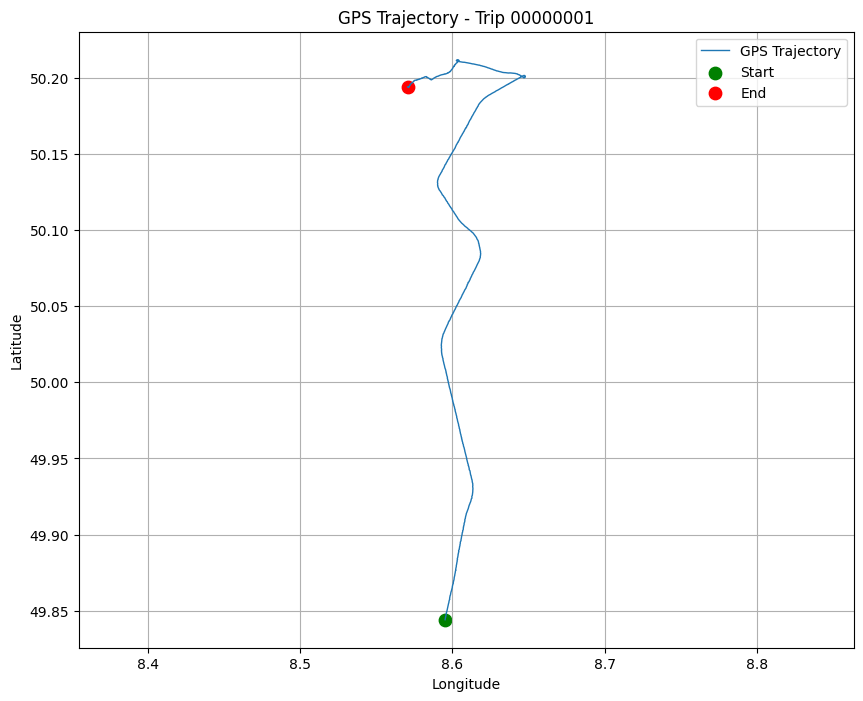

In [74]:
import matplotlib.pyplot as plt

# Select a sample trip
partition = "train"
trip_id = "00000001"

# Load the trip data
track, nodes, arcs, route = load_raw_trip(partition, trip_id)

# Plot GPS trajectory
plt.figure(figsize=(10, 8))

plt.plot(
    track["longitude"],
    track["latitude"],
    linewidth=1,
    label="GPS Trajectory"
)

# Mark starting point
plt.scatter(
    track["longitude"].iloc[0],
    track["latitude"].iloc[0],
    color="green",
    s=80,
    label="Start"
)

# Mark ending point
plt.scatter(
    track["longitude"].iloc[-1],
    track["latitude"].iloc[-1],
    color="red",
    s=80,
    label="End"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"GPS Trajectory - Trip {trip_id}")

plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


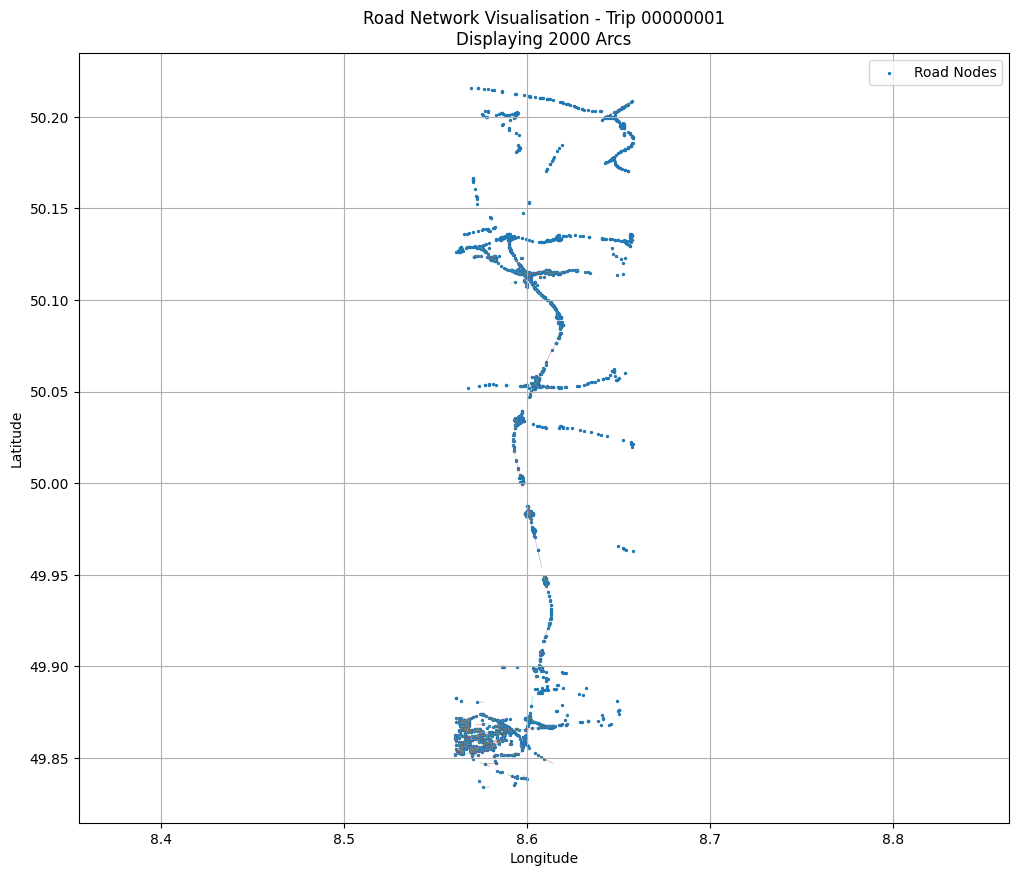

In [75]:
import matplotlib.pyplot as plt

# Load sample trip
track, nodes, arcs, route = load_raw_trip("train", "00000001")

# Select a sample of arcs
sample_size = min(2000, len(arcs))
sample_arcs = arcs.iloc[:sample_size]

plt.figure(figsize=(12, 10))

# Draw road-network connections
for _, arc in sample_arcs.iterrows():

    # Arc columns are positional: 0 = from_node, 1 = to_node
    start_node = int(arc.iloc[0])
    end_node = int(arc.iloc[1])

    # Get coordinates of connected nodes
    start_lon = nodes.iloc[start_node, 0]
    start_lat = nodes.iloc[start_node, 1]

    end_lon = nodes.iloc[end_node, 0]
    end_lat = nodes.iloc[end_node, 1]

    plt.plot(
        [start_lon, end_lon],
        [start_lat, end_lat],
        linewidth=0.5,
        alpha=0.5
    )

# Display road nodes
plt.scatter(
    nodes.iloc[:min(2000, len(nodes)), 0],
    nodes.iloc[:min(2000, len(nodes)), 1],
    s=2,
    label="Road Nodes"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    f"Road Network Visualisation - Trip 00000001\n"
    f"Displaying {sample_size} Arcs"
)

plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

In [76]:
!pip install folium

In [77]:
import folium

print("Folium version:", folium.__version__)

Folium version: 0.20.0


In [78]:
import folium

# -----------------------------------
# 1. Load trip data
# -----------------------------------

partition = "train"
trip_id = "00000001"

track, nodes, arcs, route = load_raw_trip(partition, trip_id)


# -----------------------------------
# 2. Calculate map centre
# -----------------------------------

center_lat = track.iloc[:, 1].mean()
center_lon = track.iloc[:, 0].mean()


# -----------------------------------
# 3. Create Folium map
# -----------------------------------

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=13,
    tiles=None
)

# Add Esri World Street Map tiles
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri World Street Map"
).add_to(m)


# -----------------------------------
# 4. Display road network
# -----------------------------------

sample_size = min(300, len(arcs))

for _, arc in arcs.iloc[:sample_size].iterrows():

    start_node = int(arc.iloc[0])
    end_node = int(arc.iloc[1])

    # Get node coordinates
    start_location = [
        nodes.iloc[start_node, 1],
        nodes.iloc[start_node, 0]
    ]

    end_location = [
        nodes.iloc[end_node, 1],
        nodes.iloc[end_node, 0]
    ]

    # Draw road segment
    folium.PolyLine(
        locations=[start_location, end_location],
        color="gray",
        weight=1,
        opacity=0.4,
        tooltip="Road Segment"
    ).add_to(m)


# -----------------------------------
# 5. Display GPS trajectory
# -----------------------------------

gps_locations = [
    [row.iloc[1], row.iloc[0]]
    for _, row in track.iterrows()
]

folium.PolyLine(
    locations=gps_locations,
    color="blue",
    weight=3,
    opacity=0.8,
    tooltip="GPS Trajectory"
).add_to(m)


# -----------------------------------
# 6. Mark starting location
# -----------------------------------

folium.Marker(
    location=gps_locations[0],
    popup="Starting Location",
    icon=folium.Icon(color="green")
).add_to(m)


# -----------------------------------
# 7. Mark ending location
# -----------------------------------

folium.Marker(
    location=gps_locations[-1],
    popup="Ending Location",
    icon=folium.Icon(color="red")
).add_to(m)


# -----------------------------------
# 8. Add layer control
# -----------------------------------

folium.LayerControl().add_to(m)


# -----------------------------------
# 9. Display map
# -----------------------------------

display(m)

In [79]:
m.save("PathSnap_GPS_RoadNetwork_Map.html")

print("Interactive map saved successfully!")

Interactive map saved successfully!


### 1.2 Load and Inspect GPS Observations

In this step, we load the GPS trajectory of a sample training trip.

The GPS track contains three important attributes:

- Longitude: Geographic east-west position.
- Latitude: Geographic north-south position.
- Timestamp: Time at which the GPS observation was recorded.

We first inspect the structure, data types and sample records to understand the input before calculating movement features.

In [80]:
# Load one training trip
track, nodes, arcs, route = load_raw_trip("train", "00000001")

# Display first 10 GPS observations
display(track.head(10))

# Inspect dataset structure
print("Dataset shape:", track.shape)

print("\nColumn names:")
print(track.columns.tolist())

print("\nData types:")
print(track.dtypes)

print("\nNumber of GPS observations:", len(track))

,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0
5,8.595555,49.846167,6.0
6,8.595744,49.846565,7.0
7,8.595733,49.846931,8.0
8,8.595878,49.847374,9.0
9,8.595849,49.847684,10.0


Dataset shape: (1315, 3)

Column names:
['longitude', 'latitude', 'timestamp']

Data types:
longitude    float64
latitude     float64
timestamp    float64
dtype: object

Number of GPS observations: 1315


### 1.3 Calculate Time Difference and GPS Displacement

In this step, we calculate two important GPS movement features:

1. **Time Difference (`time_difference_s`):** The time elapsed between two consecutive GPS observations.
2. **GPS Displacement (`gps_displacement_m`):** The geographical distance in metres between two consecutive GPS observations.

We use the Haversine formula to calculate the distance between GPS coordinates on the Earth's surface.

For the first observation, these values will be NaN because there is no previous observation to compare with.

In [81]:
# Reload the trip data
track, nodes, arcs, route = load_raw_trip("train", "00000001")

# Recreate the GPS working DataFrame
gps_df = track.copy()

# Assign column names
gps_df.columns = ["longitude", "latitude", "timestamp"]

# Convert columns to numeric values
gps_df = gps_df.apply(pd.to_numeric, errors="coerce")

# Reset index
gps_df = gps_df.reset_index(drop=True)

# Verify
display(gps_df.head())

print("Shape:", gps_df.shape)

,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


Shape: (1315, 3)


In [82]:
import numpy as np

# Calculate time difference between consecutive GPS observations
gps_df["time_difference_s"] = gps_df["timestamp"].diff()

# Haversine formula to calculate geographical distance
def haversine_distance(lat1, lon1, lat2, lon2):

    earth_radius = 6371000  # Earth's radius in metres

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius * c


# Calculate displacement from the previous GPS observation
gps_df["gps_displacement_m"] = haversine_distance(
    gps_df["latitude"].shift(1),
    gps_df["longitude"].shift(1),
    gps_df["latitude"],
    gps_df["longitude"]
)

# Display the calculated features
display(
    gps_df[
        [
            "longitude",
            "latitude",
            "timestamp",
            "time_difference_s",
            "gps_displacement_m"
        ]
    ].head(10)
)

,longitude,latitude,timestamp,time_difference_s,gps_displacement_m
0,8.595203,49.844053,1.0,NaN,NaN
1,8.595294,49.844441,2.0,1.0,43.634296
2,8.595352,49.844883,3.0,1.0,49.323807
3,8.595390,49.845379,4.0,1.0,55.219950
4,8.595587,49.845750,5.0,1.0,43.604720
5,8.595555,49.846167,6.0,1.0,46.425021
6,8.595744,49.846565,7.0,1.0,46.284002
7,8.595733,49.846931,8.0,1.0,40.704985
8,8.595878,49.847374,9.0,1.0,50.344574
9,8.595849,49.847684,10.0,1.0,34.533085


### 1.4 Calculate GPS Speed

GPS speed represents the distance travelled between two consecutive GPS observations divided by the time taken.

Formula:

Speed = GPS Displacement / Time Difference

The resulting speed is measured in metres per second (m/s).

The first observation will have a missing speed because there is no previous GPS observation.

In [83]:
# Calculate GPS speed in metres per second
gps_df["gps_speed_mps"] = (
    gps_df["gps_displacement_m"] /
    gps_df["time_difference_s"]
)

# Display the calculated speed
display(
    gps_df[
        [
            "timestamp",
            "time_difference_s",
            "gps_displacement_m",
            "gps_speed_mps"
        ]
    ].head(10)
)

# Basic speed statistics
print("GPS Speed Statistics:")
display(gps_df["gps_speed_mps"].describe())

,timestamp,time_difference_s,gps_displacement_m,gps_speed_mps
0,1.0,NaN,NaN,NaN
1,2.0,1.0,43.634296,43.634296
2,3.0,1.0,49.323807,49.323807
3,4.0,1.0,55.219950,55.219950
4,5.0,1.0,43.604720,43.604720
5,6.0,1.0,46.425021,46.425021
6,7.0,1.0,46.284002,46.284002
7,8.0,1.0,40.704985,40.704985
8,9.0,1.0,50.344574,50.344574
9,10.0,1.0,34.533085,34.533085


GPS Speed Statistics:


,gps_speed_mps
count,1314.000000
mean,38.020890
std,15.724695
min,1.232493
25%,25.513545
50%,41.272157
75%,50.361424
max,72.421160


In [84]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. LOAD GPS DATA
# --------------------------------------------------

track, nodes, arcs, route = load_raw_trip("train", "00000001")

gps_df = track.copy()

gps_df.columns = ["longitude", "latitude", "timestamp"]

gps_df = gps_df.apply(pd.to_numeric, errors="coerce")
gps_df = gps_df.reset_index(drop=True)


# --------------------------------------------------
# 2. TIME DIFFERENCE
# --------------------------------------------------

gps_df["time_difference_s"] = gps_df["timestamp"].diff()


# --------------------------------------------------
# 3. HAVERSINE DISTANCE
# --------------------------------------------------

def haversine_distance(lat1, lon1, lat2, lon2):

    earth_radius = 6371000

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(np.sqrt(a))


gps_df["gps_displacement_m"] = haversine_distance(
    gps_df["latitude"].shift(1),
    gps_df["longitude"].shift(1),
    gps_df["latitude"],
    gps_df["longitude"]
)


# --------------------------------------------------
# 4. GPS SPEED
# --------------------------------------------------

valid_time = gps_df["time_difference_s"] > 0

gps_df["gps_speed_mps"] = np.where(
    valid_time,
    gps_df["gps_displacement_m"] /
    gps_df["time_difference_s"],
    np.nan
)


# --------------------------------------------------
# 5. GPS ACCELERATION
# --------------------------------------------------

gps_df["gps_acceleration_mps2"] = (
    gps_df["gps_speed_mps"].diff()
    / gps_df["time_difference_s"]
)


# --------------------------------------------------
# 6. GPS HEADING / BEARING
# --------------------------------------------------

def calculate_bearing(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlon = lon2 - lon1

    x = np.sin(dlon) * np.cos(lat2)

    y = (
        np.cos(lat1) * np.sin(lat2)
        - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    )

    bearing = np.degrees(np.arctan2(x, y))

    return (bearing + 360) % 360


gps_df["gps_bearing_deg"] = calculate_bearing(
    gps_df["latitude"].shift(1),
    gps_df["longitude"].shift(1),
    gps_df["latitude"],
    gps_df["longitude"]
)

# Heading is unreliable when displacement is nearly zero
gps_df.loc[
    gps_df["gps_displacement_m"] < 0.01,
    "gps_bearing_deg"
] = np.nan

gps_df["gps_heading_sin"] = np.sin(
    np.radians(gps_df["gps_bearing_deg"])
)

gps_df["gps_heading_cos"] = np.cos(
    np.radians(gps_df["gps_bearing_deg"])
)


# --------------------------------------------------
# 7. GPS TURNING ANGLE
# --------------------------------------------------

bearing_difference = (
    gps_df["gps_bearing_deg"]
    - gps_df["gps_bearing_deg"].shift(1)
)

gps_df["gps_turning_angle_deg"] = np.abs(
    (bearing_difference + 180) % 360 - 180
)


# --------------------------------------------------
# 8. ROLLING MEAN SPEED
# --------------------------------------------------

WINDOW_SIZE = 5

gps_df["rolling_mean_speed_mps"] = (
    gps_df["gps_speed_mps"]
    .rolling(window=WINDOW_SIZE, min_periods=2)
    .mean()
)


# --------------------------------------------------
# 9. ROLLING SPEED STANDARD DEVIATION
# --------------------------------------------------

gps_df["rolling_speed_std_mps"] = (
    gps_df["gps_speed_mps"]
    .rolling(window=WINDOW_SIZE, min_periods=2)
    .std(ddof=0)
)


# --------------------------------------------------
# 10. ROLLING MEAN TURNING ANGLE
# --------------------------------------------------

gps_df["rolling_mean_turning_angle_deg"] = (
    gps_df["gps_turning_angle_deg"]
    .rolling(window=WINDOW_SIZE, min_periods=2)
    .mean()
)


# --------------------------------------------------
# 11. DISPLAY FINAL GPS FEATURES
# --------------------------------------------------

gps_feature_columns = [
    "time_difference_s",
    "gps_displacement_m",
    "gps_speed_mps",
    "gps_acceleration_mps2",
    "gps_heading_sin",
    "gps_heading_cos",
    "gps_turning_angle_deg",
    "rolling_mean_speed_mps",
    "rolling_speed_std_mps",
    "rolling_mean_turning_angle_deg"
]

print("GPS Feature Engineering Completed!")
print("Total GPS observations:", len(gps_df))
print("Total GPS movement features:", len(gps_feature_columns))

display(
    gps_df[
        ["longitude", "latitude", "timestamp"]
        + gps_feature_columns
    ].head(15)
)

GPS Feature Engineering Completed!
Total GPS observations: 1315
Total GPS movement features: 10


,longitude,latitude,timestamp,time_difference_s,gps_displacement_m,gps_speed_mps,gps_acceleration_mps2,gps_heading_sin,gps_heading_cos,gps_turning_angle_deg,rolling_mean_speed_mps,rolling_speed_std_mps,rolling_mean_turning_angle_deg
0,8.595203,49.844053,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8.595294,49.844441,2.0,1.0,43.634296,43.634296,NaN,0.149543,0.988755,NaN,NaN,NaN,NaN
2,8.595352,49.844883,3.0,1.0,49.323807,49.323807,5.689511,0.084318,0.996439,3.763648,46.479052,2.844756,NaN
3,8.595390,49.845379,4.0,1.0,55.219950,55.219950,5.896143,0.049344,0.998782,2.008476,49.392685,4.730074,2.886062
4,8.595587,49.845750,5.0,1.0,43.604720,43.604720,-11.615230,0.323948,0.946075,16.073486,47.945693,4.802245,7.281870
5,8.595555,49.846167,6.0,1.0,46.425021,46.425021,2.820301,-0.049424,0.998778,21.734758,47.641559,4.338114,10.895092
6,8.595744,49.846565,7.0,1.0,46.284002,46.284002,-0.141019,0.292796,0.956175,19.858373,48.171500,3.961737,12.687748
7,8.595733,49.846931,8.0,1.0,40.704985,40.704985,-5.579017,-0.019377,0.999812,18.135707,46.447736,4.858827,15.562160
8,8.595878,49.847374,9.0,1.0,50.344574,50.344574,9.639589,0.206511,0.978444,13.028219,45.472661,3.210007,17.766109
9,8.595849,49.847684,10.0,1.0,34.533085,34.533085,-15.811489,-0.060213,0.998186,15.369970,43.658334,5.499944,17.625406


## Stage 2 – Road Network Preprocessing and Topology Features

This stage processes the directed road network.

Each road arc connects a starting node to an ending node.

We calculate:
- Indegree: Number of incoming directed arcs.
- Outdegree: Number of outgoing directed arcs.

These values are calculated once for each node in the trip's road network.

The resulting node-level topology information will later be associated with candidate road segments.

In [85]:
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. LOAD ROAD NETWORK
# --------------------------------------------------

track, nodes, arcs, route = load_raw_trip("train", "00000001")

# Assign meaningful column names
nodes_df = nodes.copy()
nodes_df.columns = ["longitude", "latitude"]

arcs_df = arcs.copy()
arcs_df.columns = ["from_node_id", "to_node_id"]

# Convert IDs to integers
arcs_df["from_node_id"] = arcs_df["from_node_id"].astype(int)
arcs_df["to_node_id"] = arcs_df["to_node_id"].astype(int)

# --------------------------------------------------
# 2. CALCULATE NODE INDEGREE
# --------------------------------------------------

node_indegree = (
    arcs_df.groupby("to_node_id")
    .size()
)

# --------------------------------------------------
# 3. CALCULATE NODE OUTDEGREE
# --------------------------------------------------

node_outdegree = (
    arcs_df.groupby("from_node_id")
    .size()
)

# --------------------------------------------------
# 4. CREATE NODE TOPOLOGY TABLE
# --------------------------------------------------

node_topology_df = pd.DataFrame({
    "node_id": range(len(nodes_df))
})

node_topology_df["indegree"] = (
    node_topology_df["node_id"]
    .map(node_indegree)
    .fillna(0)
    .astype(int)
)

node_topology_df["outdegree"] = (
    node_topology_df["node_id"]
    .map(node_outdegree)
    .fillna(0)
    .astype(int)
)

# --------------------------------------------------
# 5. DISPLAY NODE TOPOLOGY INFORMATION
# --------------------------------------------------

print("Road Network Topology Processing Completed!")

print("Total road nodes:", len(nodes_df))
print("Total directed arcs:", len(arcs_df))

display(node_topology_df.head(10))

# --------------------------------------------------
# 6. TOPOLOGY SUMMARY
# --------------------------------------------------

print("\nTopology Statistics:")

display(
    node_topology_df[
        ["indegree", "outdegree"]
    ].describe()
)

print(
    "\nNodes with no incoming arcs:",
    (node_topology_df["indegree"] == 0).sum()
)

print(
    "Nodes with no outgoing arcs:",
    (node_topology_df["outdegree"] == 0).sum()
)

Road Network Topology Processing Completed!
Total road nodes: 88809
Total directed arcs: 165790


,node_id,indegree,outdegree
0,0,3,3
1,1,4,4
2,2,3,3
3,3,4,4
4,4,3,3
5,5,4,4
6,6,2,2
7,7,4,4
8,8,4,4
9,9,3,3



Topology Statistics:


,indegree,outdegree
count,88809.000000,88809.000000
mean,1.866815,1.866815
std,0.747821,0.748047
min,0.000000,0.000000
25%,1.000000,1.000000
50%,2.000000,2.000000
75%,2.000000,2.000000
max,6.000000,6.000000



Nodes with no incoming arcs: 69
Nodes with no outgoing arcs: 81


## Stage 3 – Candidate Road Generation

Candidate road generation identifies possible road segments for every GPS observation.

A spatial index is used to efficiently search nearby road segments instead of checking every road segment individually.

The road network and GPS coordinates are projected into a suitable metric coordinate system so that distances can be calculated in metres.

For every GPS observation, we:
1. Search for nearby road segments.
2. Calculate the GPS-to-road-segment distance.
3. Retain candidates within a configurable radius.
4. Store the GPS index, candidate arc ID and distance.

The reference route is not used during candidate generation.

In [86]:
import numpy as np
import pandas as pd

from pyproj import Transformer
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree


# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

SEARCH_RADIUS_M = 50

partition = "train"
trip_id = "00000001"


# --------------------------------------------------
# 2. LOAD TRIP DATA
# --------------------------------------------------

track, nodes, arcs, route = load_raw_trip(partition, trip_id)

gps_df = track.copy()
gps_df.columns = ["longitude", "latitude", "timestamp"]

gps_df = gps_df.apply(pd.to_numeric, errors="coerce")
gps_df = gps_df.reset_index(drop=True)

nodes_df = nodes.copy()
nodes_df.columns = ["longitude", "latitude"]

arcs_df = arcs.copy()
arcs_df.columns = ["from_node_id", "to_node_id"]

arcs_df = arcs_df.astype(int)


# --------------------------------------------------
# 3. CREATE PROJECTED COORDINATE SYSTEM
# --------------------------------------------------

mean_lon = nodes_df["longitude"].mean()
mean_lat = nodes_df["latitude"].mean()

utm_zone = int((mean_lon + 180) // 6) + 1

epsg_code = (
    32600 + utm_zone if mean_lat >= 0
    else 32700 + utm_zone
)

transformer = Transformer.from_crs(
    "EPSG:4326",
    f"EPSG:{epsg_code}",
    always_xy=True
)

print("Using projected CRS:", f"EPSG:{epsg_code}")


# --------------------------------------------------
# 4. PROJECT ROAD NODES
# --------------------------------------------------

node_x, node_y = transformer.transform(
    nodes_df["longitude"].to_numpy(),
    nodes_df["latitude"].to_numpy()
)

projected_nodes = np.column_stack((node_x, node_y))


# --------------------------------------------------
# 5. CREATE ROAD SEGMENT GEOMETRIES
# --------------------------------------------------

road_geometries = []

for arc in arcs_df.itertuples(index=False):

    start_node = arc.from_node_id
    end_node = arc.to_node_id

    start_x, start_y = projected_nodes[start_node]
    end_x, end_y = projected_nodes[end_node]

    road_segment = LineString([
        (start_x, start_y),
        (end_x, end_y)
    ])

    road_geometries.append(road_segment)


# --------------------------------------------------
# 6. BUILD SPATIAL INDEX
# --------------------------------------------------

road_tree = STRtree(road_geometries)

# Supports both Shapely 2.x and older versions
shapely_version = int(
    __import__("shapely").__version__.split(".")[0]
)

geometry_id_to_arc_id = {
    id(geometry): arc_id
    for arc_id, geometry in enumerate(road_geometries)
}


# --------------------------------------------------
# 7. GENERATE CANDIDATE ROADS
# --------------------------------------------------

candidate_records = []

for gps_index, gps_row in gps_df.iterrows():

    gps_x, gps_y = transformer.transform(
        gps_row["longitude"],
        gps_row["latitude"]
    )

    gps_point = Point(gps_x, gps_y)

    search_area = gps_point.buffer(SEARCH_RADIUS_M)

    nearby_results = road_tree.query(search_area)

    for result in nearby_results:

        if shapely_version >= 2:
            arc_id = int(result)
            road_segment = road_geometries[arc_id]

        else:
            road_segment = result
            arc_id = geometry_id_to_arc_id[id(road_segment)]

        distance = gps_point.distance(road_segment)

        if distance <= SEARCH_RADIUS_M:

            candidate_records.append({
                "trip_id": trip_id,
                "gps_index": gps_index,
                "candidate_arc_id": arc_id,
                "gps_road_distance_m": distance
            })


# --------------------------------------------------
# 8. CREATE CANDIDATE DATAFRAME
# --------------------------------------------------

candidate_df = pd.DataFrame(
    candidate_records,
    columns=[
        "trip_id",
        "gps_index",
        "candidate_arc_id",
        "gps_road_distance_m"
    ]
)


# --------------------------------------------------
# 9. CANDIDATE GENERATION SUMMARY
# --------------------------------------------------

candidate_counts = (
    candidate_df.groupby("gps_index")
    .size()
    .reindex(range(len(gps_df)), fill_value=0)
)

print("\nCandidate Road Generation Completed!")

print("Total GPS observations:", len(gps_df))
print("Total road segments:", len(arcs_df))
print("Search radius:", SEARCH_RADIUS_M, "metres")
print("Total candidate pairs:", len(candidate_df))

print(
    "GPS observations with at least one candidate:",
    (candidate_counts > 0).sum()
)

print(
    "GPS observations with no candidates:",
    (candidate_counts == 0).sum()
)

print(
    "Average candidates per GPS observation:",
    round(candidate_counts.mean(), 2)
)

print("\nCandidate Count Statistics:")

display(candidate_counts.describe())

print("\nFirst 15 Candidate Pairs:")

display(candidate_df.head(15))

Using projected CRS: EPSG:32632

Candidate Road Generation Completed!
Total GPS observations: 1315
Total road segments: 165790
Search radius: 50 metres
Total candidate pairs: 15964
GPS observations with at least one candidate: 1315
GPS observations with no candidates: 0
Average candidates per GPS observation: 12.14

Candidate Count Statistics:


,0
count,1315.000000
mean,12.139924
std,9.517118
min,2.000000
25%,5.000000
50%,10.000000
75%,16.000000
max,80.000000



First 15 Candidate Pairs:


,trip_id,gps_index,candidate_arc_id,gps_road_distance_m
0,00000001,0,2641,32.198445
1,00000001,0,117639,15.132321
2,00000001,0,64973,0.722768
3,00000001,1,117639,16.079744
4,00000001,1,64973,0.277461
5,00000001,2,117639,13.902872
6,00000001,2,64973,1.839765
7,00000001,3,117639,9.528681
8,00000001,3,64973,6.147324
9,00000001,4,117639,18.276541


## Stage 4 – Candidate Road Geometry and Directional Feature Engineering

This stage calculates geometric and directional properties for every GPS observation–candidate road pair.

The features include:
- GPS-to-road perpendicular distance
- Projection fraction along the road segment
- Distance to starting and ending nodes
- Road segment length
- Directed road bearing represented using sine and cosine

All geographical calculations use projected coordinates in metres.

Each candidate is identified using its GPS observation index and candidate arc ID.

In [87]:
import numpy as np
import pandas as pd

from shapely.geometry import Point, LineString


# --------------------------------------------------
# 1. RELOAD AND PREPARE TRIP DATA
# --------------------------------------------------

partition = "train"
trip_id = "00000001"

track, nodes, arcs, route = load_raw_trip(partition, trip_id)

gps_df = track.copy()
gps_df.columns = ["longitude", "latitude", "timestamp"]

gps_df = gps_df.apply(pd.to_numeric, errors="coerce")
gps_df = gps_df.reset_index(drop=True)

nodes_df = nodes.copy()
nodes_df.columns = ["longitude", "latitude"]

arcs_df = arcs.copy()
arcs_df.columns = ["from_node_id", "to_node_id"]

arcs_df = arcs_df.astype(int)


# --------------------------------------------------
# 2. RECREATE PROJECTED COORDINATES
# --------------------------------------------------

from pyproj import Transformer

mean_lon = nodes_df["longitude"].mean()
mean_lat = nodes_df["latitude"].mean()

utm_zone = int((mean_lon + 180) // 6) + 1

epsg_code = (
    32600 + utm_zone if mean_lat >= 0
    else 32700 + utm_zone
)

transformer = Transformer.from_crs(
    "EPSG:4326",
    f"EPSG:{epsg_code}",
    always_xy=True
)

node_x, node_y = transformer.transform(
    nodes_df["longitude"].to_numpy(),
    nodes_df["latitude"].to_numpy()
)

projected_nodes = np.column_stack((node_x, node_y))


# --------------------------------------------------
# 3. RECREATE CANDIDATE DATAFRAME
# --------------------------------------------------

# Candidate generation is repeated here to make
# Stage 4 independently executable.

from shapely.strtree import STRtree

road_geometries = []

for arc in arcs_df.itertuples(index=False):

    start_node = arc.from_node_id
    end_node = arc.to_node_id

    road_geometries.append(
        LineString([
            projected_nodes[start_node],
            projected_nodes[end_node]
        ])
    )

road_tree = STRtree(road_geometries)

SEARCH_RADIUS_M = 50

candidate_records = []

for gps_index, gps_row in gps_df.iterrows():

    gps_x, gps_y = transformer.transform(
        gps_row["longitude"],
        gps_row["latitude"]
    )

    gps_point = Point(gps_x, gps_y)

    nearby_arc_ids = road_tree.query(
        gps_point.buffer(SEARCH_RADIUS_M)
    )

    for arc_id in nearby_arc_ids:

        arc_id = int(arc_id)

        road_segment = road_geometries[arc_id]

        distance = gps_point.distance(road_segment)

        if distance <= SEARCH_RADIUS_M:

            candidate_records.append({
                "trip_id": trip_id,
                "gps_index": gps_index,
                "candidate_arc_id": arc_id,
                "gps_road_distance_m": distance
            })

candidate_df = pd.DataFrame(candidate_records)


# --------------------------------------------------
# 4. CALCULATE CANDIDATE ROAD FEATURES
# --------------------------------------------------

geometry_records = []

for candidate in candidate_df.itertuples(index=False):

    gps_index = candidate.gps_index
    arc_id = candidate.candidate_arc_id

    gps_row = gps_df.iloc[gps_index]

    gps_x, gps_y = transformer.transform(
        gps_row["longitude"],
        gps_row["latitude"]
    )

    gps_point = Point(gps_x, gps_y)

    road_segment = road_geometries[arc_id]

    start_node_id = arcs_df.iloc[arc_id, 0]
    end_node_id = arcs_df.iloc[arc_id, 1]

    start_x, start_y = projected_nodes[start_node_id]
    end_x, end_y = projected_nodes[end_node_id]

    start_point = Point(start_x, start_y)
    end_point = Point(end_x, end_y)

    # Projection distance along the directed segment
    segment_length = road_segment.length

    if segment_length > 0:

        projection_fraction = (
            road_segment.project(gps_point, normalized=True)
        )

        # Clamp projection to the finite road segment
        projection_fraction = np.clip(
            projection_fraction, 0, 1
        )

        # Directed bearing: start node to end node
        dx = end_x - start_x
        dy = end_y - start_y

        road_bearing_deg = (
            np.degrees(np.arctan2(dx, dy)) + 360
        ) % 360

        road_bearing_sin = np.sin(
            np.radians(road_bearing_deg)
        )

        road_bearing_cos = np.cos(
            np.radians(road_bearing_deg)
        )

    else:

        projection_fraction = np.nan
        road_bearing_deg = np.nan
        road_bearing_sin = np.nan
        road_bearing_cos = np.nan

    geometry_records.append({

        "trip_id": trip_id,

        "gps_index": gps_index,

        "candidate_arc_id": arc_id,

        "gps_road_distance_m": gps_point.distance(
            road_segment
        ),

        "projection_fraction": projection_fraction,

        "distance_to_start_node_m": gps_point.distance(
            start_point
        ),

        "distance_to_end_node_m": gps_point.distance(
            end_point
        ),

        "road_segment_length_m": segment_length,

        "road_bearing_sin": road_bearing_sin,

        "road_bearing_cos": road_bearing_cos

    })


# --------------------------------------------------
# 5. CREATE FINAL GEOMETRY FEATURE TABLE
# --------------------------------------------------

candidate_geometry_df = pd.DataFrame(geometry_records)


# --------------------------------------------------
# 6. DISPLAY RESULTS
# --------------------------------------------------

geometry_feature_columns = [

    "gps_road_distance_m",

    "projection_fraction",

    "distance_to_start_node_m",

    "distance_to_end_node_m",

    "road_segment_length_m",

    "road_bearing_sin",

    "road_bearing_cos"

]

print("Stage 4 – Candidate Road Feature Engineering Completed!")

print("Total GPS observations:", len(gps_df))

print("Total candidate pairs:", len(candidate_geometry_df))

print("Total geometry and directional features:",
      len(geometry_feature_columns))

print("\nFirst 15 Candidate Geometry Records:")

display(candidate_geometry_df.head(15))

print("\nFeature Statistics:")

display(
    candidate_geometry_df[
        geometry_feature_columns
    ].describe()
)

print("\nMissing Values:")

display(
    candidate_geometry_df[
        geometry_feature_columns
    ].isnull().sum()
)

Stage 4 – Candidate Road Feature Engineering Completed!
Total GPS observations: 1315
Total candidate pairs: 15964
Total geometry and directional features: 7

First 15 Candidate Geometry Records:


,trip_id,gps_index,candidate_arc_id,gps_road_distance_m,projection_fraction,distance_to_start_node_m,distance_to_end_node_m,road_segment_length_m,road_bearing_sin,road_bearing_cos
0,00000001,0,2641,32.198445,1.000000,457.242638,32.198445,425.050298,0.130372,0.991465
1,00000001,0,117639,15.132321,0.512692,523.389298,497.497803,1020.438110,-0.133803,-0.991008
2,00000001,0,64973,0.722768,0.109775,32.198445,261.048608,293.237939,0.132603,0.991169
3,00000001,1,117639,16.079744,0.469944,479.818048,541.128530,1020.438110,-0.133803,-0.991008
4,00000001,1,64973,0.277461,0.258531,75.811621,217.427003,293.237939,0.132603,0.991169
5,00000001,2,117639,13.902872,0.421659,430.501773,590.324627,1020.438110,-0.133803,-0.991008
6,00000001,2,64973,1.839765,0.426565,125.098559,168.162973,293.237939,0.132603,0.991169
7,00000001,3,117639,9.528681,0.367721,375.357447,645.271986,1020.438110,-0.133803,-0.991008
8,00000001,3,64973,6.147324,0.614283,180.235888,113.273845,293.237939,0.132603,0.991169
9,00000001,4,117639,18.276541,0.325850,333.011938,688.170820,1020.438110,-0.133803,-0.991008



Feature Statistics:


,gps_road_distance_m,projection_fraction,distance_to_start_node_m,distance_to_end_node_m,road_segment_length_m,road_bearing_sin,road_bearing_cos
count,15964.000000,15964.000000,15964.000000,15964.000000,15964.000000,15964.000000,15964.000000
mean,27.989438,0.499932,69.323205,69.879828,94.149448,0.003958,0.018472
std,14.359541,0.438688,97.574801,99.978504,162.187468,0.624418,0.780902
min,0.004101,0.000000,0.834542,0.834542,0.420427,-1.000000,-1.000000
25%,16.233829,0.000000,30.148929,30.148929,15.773460,-0.534276,-0.818224
50%,29.627745,0.499306,43.928379,43.932478,40.221989,0.011550,0.075763
75%,40.533280,1.000000,65.899561,65.878079,99.781547,0.557770,0.853884
max,49.992309,1.000000,1155.421083,1135.222713,1106.736679,1.000000,1.000000



Missing Values:


,0
gps_road_distance_m,0
projection_fraction,0
distance_to_start_node_m,0
distance_to_end_node_m,0
road_segment_length_m,0
road_bearing_sin,0
road_bearing_cos,0


# Stage 5: Final Pairwise Feature Table

The objective of this stage is to combine GPS movement features, candidate-road geometry features, and road-network topology features into a unified dataset.

Each row represents a GPS-observation/candidate-road pair.

The final dataset contains:

1. GPS movement features:
   - gps_speed_mps
   - gps_acceleration_mps2
   - gps_heading_sin
   - gps_heading_cos
   - gps_turning_angle_deg
   - time_difference_s
   - gps_displacement_m
   - rolling_mean_speed_mps
   - rolling_speed_std_mps
   - rolling_mean_turning_angle_deg

2. Candidate-road geometry features:
   - gps_road_distance_m
   - projection_fraction
   - distance_to_start_node_m
   - distance_to_end_node_m
   - road_segment_length_m
   - road_bearing_sin
   - road_bearing_cos
   - heading_difference_deg

3. Road-network topology features:
   - start_node_indegree
   - start_node_outdegree
   - end_node_indegree
   - end_node_outdegree

The final table will preserve the metadata columns:
- trip_id
- gps_index
- candidate_arc_id

The metadata columns identify each observation-candidate pair and are not treated as predictive features.

Undefined feature values will remain NaN. They will not be arbitrarily replaced with zero.

In [89]:
import numpy as np
import pandas as pd

# Reload the GPS data
track, nodes, arcs, route = load_raw_trip("train", "00000001")

gps_df = track.copy()
gps_df.columns = ["longitude", "latitude", "timestamp"]
gps_df = gps_df.apply(pd.to_numeric, errors="coerce").reset_index(drop=True)

# Time difference
gps_df["time_difference_s"] = gps_df["timestamp"].diff()

# Haversine distance
def haversine_distance(lat1, lon1, lat2, lon2):
    earth_radius = 6371000

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(np.sqrt(a))


gps_df["gps_displacement_m"] = haversine_distance(
    gps_df["latitude"].shift(1),
    gps_df["longitude"].shift(1),
    gps_df["latitude"],
    gps_df["longitude"]
)

# Speed
valid_time = gps_df["time_difference_s"] > 0

gps_df["gps_speed_mps"] = np.where(
    valid_time,
    gps_df["gps_displacement_m"] / gps_df["time_difference_s"],
    np.nan
)

# Acceleration
gps_df["gps_acceleration_mps2"] = (
    gps_df["gps_speed_mps"].diff()
    / gps_df["time_difference_s"]
)

# GPS bearing
def calculate_bearing(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlon = lon2 - lon1

    x = np.sin(dlon) * np.cos(lat2)

    y = (
        np.cos(lat1) * np.sin(lat2)
        - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    )

    bearing = np.degrees(np.arctan2(x, y))

    return (bearing + 360) % 360


gps_df["gps_bearing_deg"] = calculate_bearing(
    gps_df["latitude"].shift(1),
    gps_df["longitude"].shift(1),
    gps_df["latitude"],
    gps_df["longitude"]
)

gps_df.loc[
    gps_df["gps_displacement_m"] < 0.01,
    "gps_bearing_deg"
] = np.nan

# Heading encoding
gps_df["gps_heading_sin"] = np.sin(
    np.radians(gps_df["gps_bearing_deg"])
)

gps_df["gps_heading_cos"] = np.cos(
    np.radians(gps_df["gps_bearing_deg"])
)

# Turning angle
bearing_difference = (
    gps_df["gps_bearing_deg"]
    - gps_df["gps_bearing_deg"].shift(1)
)

gps_df["gps_turning_angle_deg"] = np.abs(
    (bearing_difference + 180) % 360 - 180
)

# Rolling features
WINDOW_SIZE = 5

gps_df["rolling_mean_speed_mps"] = (
    gps_df["gps_speed_mps"]
    .rolling(WINDOW_SIZE, min_periods=2)
    .mean()
)

gps_df["rolling_speed_std_mps"] = (
    gps_df["gps_speed_mps"]
    .rolling(WINDOW_SIZE, min_periods=2)
    .std(ddof=0)
)

gps_df["rolling_mean_turning_angle_deg"] = (
    gps_df["gps_turning_angle_deg"]
    .rolling(WINDOW_SIZE, min_periods=2)
    .mean()
)

print("Stage 1 GPS features restored.")
print("GPS DataFrame shape:", gps_df.shape)

display(gps_df.head())

Stage 1 GPS features restored.
GPS DataFrame shape: (1315, 14)


,longitude,latitude,timestamp,time_difference_s,gps_displacement_m,gps_speed_mps,gps_acceleration_mps2,gps_bearing_deg,gps_heading_sin,gps_heading_cos,gps_turning_angle_deg,rolling_mean_speed_mps,rolling_speed_std_mps,rolling_mean_turning_angle_deg
0,8.595203,49.844053,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8.595294,49.844441,2.0,1.0,43.634296,43.634296,NaN,8.600467,0.149543,0.988755,NaN,NaN,NaN,NaN
2,8.595352,49.844883,3.0,1.0,49.323807,49.323807,5.689511,4.836819,0.084318,0.996439,3.763648,46.479052,2.844756,NaN
3,8.595390,49.845379,4.0,1.0,55.219950,55.219950,5.896143,2.828343,0.049344,0.998782,2.008476,49.392685,4.730074,2.886062
4,8.595587,49.845750,5.0,1.0,43.604720,43.604720,-11.615230,18.901829,0.323948,0.946075,16.073486,47.945693,4.802245,7.281870


In [90]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

TRIP_ID = "00000001"

# The 20 required features plus 2 recommended
# circular-encoding companion features.
FEATURE_COLUMNS = [
    # GPS movement features
    "gps_speed_mps",
    "gps_acceleration_mps2",
    "gps_heading_sin",
    "gps_turning_angle_deg",
    "time_difference_s",
    "gps_displacement_m",
    "rolling_mean_speed_mps",

    # Candidate-road geometry features
    "gps_road_distance_m",
    "projection_fraction",
    "distance_to_start_node_m",
    "distance_to_end_node_m",
    "road_segment_length_m",
    "road_bearing_sin",
    "heading_difference_deg",

    # Road-network topology features
    "start_node_indegree",
    "start_node_outdegree",
    "end_node_indegree",
    "end_node_outdegree",

    # Local trajectory context
    "rolling_speed_std_mps",
    "rolling_mean_turning_angle_deg",

    # Recommended circular-encoding companions
    "gps_heading_cos",
    "road_bearing_cos"
]

METADATA_COLUMNS = [
    "trip_id",
    "gps_index",
    "candidate_arc_id"
]


# --------------------------------------------------
# 2. CHECK REQUIRED STAGE OUTPUTS
# --------------------------------------------------

required_variables = [
    "gps_df",
    "node_topology_df",
    "candidate_geometry_df",
    "arcs"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Run its corresponding "
            "previous stage before Stage 5."
        )

required_gps_columns = [
    "gps_speed_mps",
    "gps_acceleration_mps2",
    "gps_heading_sin",
    "gps_heading_cos",
    "gps_turning_angle_deg",
    "time_difference_s",
    "gps_displacement_m",
    "rolling_mean_speed_mps",
    "rolling_speed_std_mps",
    "rolling_mean_turning_angle_deg"
]

required_geometry_columns = [
    "gps_index",
    "candidate_arc_id",
    "gps_road_distance_m",
    "projection_fraction",
    "distance_to_start_node_m",
    "distance_to_end_node_m",
    "road_segment_length_m",
    "road_bearing_sin",
    "road_bearing_cos"
]

for column in required_gps_columns:
    if column not in gps_df.columns:
        raise ValueError(f"Missing GPS feature: {column}")

for column in required_geometry_columns:
    if column not in candidate_geometry_df.columns:
        raise ValueError(f"Missing geometry feature: {column}")

if not {"node_id", "indegree", "outdegree"}.issubset(
    node_topology_df.columns
):
    raise ValueError("Node topology table has unexpected columns.")

if arcs.shape[1] < 2:
    raise ValueError("Arc table must contain two endpoint columns.")


# --------------------------------------------------
# 3. PREPARE GPS MOVEMENT FEATURES
# --------------------------------------------------

gps_features = gps_df[required_gps_columns].copy()

gps_features["gps_index"] = np.arange(len(gps_features))

# Each GPS observation has exactly one movement-feature row.
assert gps_features["gps_index"].is_unique


# --------------------------------------------------
# 4. PREPARE CANDIDATE-ROAD GEOMETRY FEATURES
# --------------------------------------------------

pair_features = candidate_geometry_df[
    required_geometry_columns
].copy()

pair_features["gps_index"] = pair_features[
    "gps_index"
].astype(int)

pair_features["candidate_arc_id"] = pair_features[
    "candidate_arc_id"
].astype(int)

# Candidate arc IDs are row indices in the current trip's .arcs file.
arc_ids = pair_features["candidate_arc_id"].to_numpy()

if len(arc_ids) == 0:
    raise ValueError("No candidate pairs are available.")

if np.any(arc_ids < 0) or np.any(arc_ids >= len(arcs)):
    raise ValueError("Candidate table contains invalid arc IDs.")


# --------------------------------------------------
# 5. GET START AND END NODE IDs FOR EACH CANDIDATE
# --------------------------------------------------

arc_array = arcs.iloc[:, :2].to_numpy(dtype=int)

pair_features["start_node_id"] = arc_array[arc_ids, 0]
pair_features["end_node_id"] = arc_array[arc_ids, 1]


# --------------------------------------------------
# 6. ATTACH DIRECTED NODE TOPOLOGY FEATURES
# --------------------------------------------------

topology_lookup = node_topology_df.set_index("node_id")

start_nodes = pair_features["start_node_id"]
end_nodes = pair_features["end_node_id"]

pair_features["start_node_indegree"] = (
    start_nodes.map(topology_lookup["indegree"])
)

pair_features["start_node_outdegree"] = (
    start_nodes.map(topology_lookup["outdegree"])
)

pair_features["end_node_indegree"] = (
    end_nodes.map(topology_lookup["indegree"])
)

pair_features["end_node_outdegree"] = (
    end_nodes.map(topology_lookup["outdegree"])
)

if pair_features[
    [
        "start_node_indegree",
        "start_node_outdegree",
        "end_node_indegree",
        "end_node_outdegree"
    ]
].isna().any().any():
    raise ValueError(
        "Some candidate endpoint nodes are missing from "
        "the topology table."
    )


# --------------------------------------------------
# 7. CALCULATE GPS-TO-ROAD HEADING DIFFERENCE
# --------------------------------------------------

# Recover GPS heading from its sine and cosine components.
gps_heading_deg = np.degrees(
    np.arctan2(
        gps_features["gps_heading_sin"],
        gps_features["gps_heading_cos"]
    )
)

# Recover directed road bearing from its sine and cosine.
road_bearing_deg = np.degrees(
    np.arctan2(
        pair_features["road_bearing_sin"],
        pair_features["road_bearing_cos"]
    )
)

# Match each candidate pair to its GPS observation's heading.
matched_gps_heading = pair_features["gps_index"].map(
    pd.Series(
        gps_heading_deg.to_numpy(),
        index=gps_features["gps_index"]
    )
).to_numpy()

# Smallest absolute angular difference in [0, 180].
heading_difference = np.abs(
    (matched_gps_heading - road_bearing_deg.to_numpy() + 180)
    % 360 - 180
)

pair_features["heading_difference_deg"] = heading_difference

# Keep heading difference missing when GPS heading is unavailable.
pair_features.loc[
    pd.isna(matched_gps_heading),
    "heading_difference_deg"
] = np.nan


# --------------------------------------------------
# 8. MERGE GPS FEATURES WITH CANDIDATE FEATURES
# --------------------------------------------------

final_feature_df = pair_features.merge(
    gps_features,
    on="gps_index",
    how="left",
    validate="many_to_one"
)

# Add trip metadata.
final_feature_df.insert(0, "trip_id", TRIP_ID)

# Remove internal node IDs: they are used for lookup,
# not included as predictive features.
final_feature_df = final_feature_df.drop(
    columns=["start_node_id", "end_node_id"]
)


# --------------------------------------------------
# 9. SELECT FINAL COLUMN ORDER
# --------------------------------------------------

final_columns = METADATA_COLUMNS + FEATURE_COLUMNS

final_feature_df = final_feature_df[final_columns].copy()

# Ensure all model features are numeric.
final_feature_df[FEATURE_COLUMNS] = (
    final_feature_df[FEATURE_COLUMNS].apply(
        pd.to_numeric,
        errors="coerce"
    )
)


# --------------------------------------------------
# 10. VALIDATION
# --------------------------------------------------

print("FINAL PAIRWISE FEATURE TABLE")
print("=" * 60)

print("Trip ID:", TRIP_ID)
print("Total GPS observations:", len(gps_df))
print("Total candidate pairs:", len(final_feature_df))
print("Total feature columns:", len(FEATURE_COLUMNS))
print("Total metadata columns:", len(METADATA_COLUMNS))

print("\nFinal dataset shape:")
print(final_feature_df.shape)

print("\nFirst 10 rows:")
display(final_feature_df.head(10))

print("\nFeature column list:")
print(FEATURE_COLUMNS)

print("\nMissing values per feature:")
display(
    final_feature_df[FEATURE_COLUMNS]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

print("\nDuplicate GPS-candidate pairs:")
print(
    final_feature_df.duplicated(
        subset=["trip_id", "gps_index", "candidate_arc_id"]
    ).sum()
)

print("\nCandidate pairs per GPS observation:")
display(
    final_feature_df.groupby("gps_index")
    .size()
    .describe()
)

# Check that every GPS observation has at least one candidate.
candidate_counts = final_feature_df.groupby("gps_index").size()

print(
    "\nGPS observations without candidates:",
    len(gps_df) - candidate_counts.index.nunique()
)

print("\nStage 5 completed.")

FINAL PAIRWISE FEATURE TABLE
Trip ID: 00000001
Total GPS observations: 1315
Total candidate pairs: 15964
Total feature columns: 22
Total metadata columns: 3

Final dataset shape:
(15964, 25)

First 10 rows:


,trip_id,gps_index,candidate_arc_id,gps_speed_mps,gps_acceleration_mps2,gps_heading_sin,gps_turning_angle_deg,time_difference_s,gps_displacement_m,rolling_mean_speed_mps,...,road_bearing_sin,heading_difference_deg,start_node_indegree,start_node_outdegree,end_node_indegree,end_node_outdegree,rolling_speed_std_mps,rolling_mean_turning_angle_deg,gps_heading_cos,road_bearing_cos
0,00000001,0,2641,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.130372,NaN,1,1,1,1,NaN,NaN,NaN,0.991465
1,00000001,0,117639,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.133803,NaN,1,1,1,1,NaN,NaN,NaN,-0.991008
2,00000001,0,64973,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.132603,NaN,1,1,1,1,NaN,NaN,NaN,0.991169
3,00000001,1,117639,43.634296,NaN,0.149543,NaN,1.0,43.634296,NaN,...,-0.133803,179.088920,1,1,1,1,NaN,NaN,0.988755,-0.991008
4,00000001,1,64973,43.634296,NaN,0.149543,NaN,1.0,43.634296,NaN,...,0.132603,0.980439,1,1,1,1,NaN,NaN,0.988755,0.991169
5,00000001,2,117639,49.323807,5.689511,0.084318,3.763648,1.0,49.323807,46.479052,...,-0.133803,177.147432,1,1,1,1,2.844756,NaN,0.996439,-0.991008
6,00000001,2,64973,49.323807,5.689511,0.084318,3.763648,1.0,49.323807,46.479052,...,0.132603,2.783209,1,1,1,1,2.844756,NaN,0.996439,0.991169
7,00000001,3,117639,55.219950,5.896143,0.049344,2.008476,1.0,55.219950,49.392685,...,-0.133803,175.138956,1,1,1,1,4.730074,2.886062,0.998782,-0.991008
8,00000001,3,64973,55.219950,5.896143,0.049344,2.008476,1.0,55.219950,49.392685,...,0.132603,4.791685,1,1,1,1,4.730074,2.886062,0.998782,0.991169
9,00000001,4,117639,43.604720,-11.615230,0.323948,16.073486,1.0,43.604720,47.945693,...,-0.133803,168.787558,1,1,1,1,4.802245,7.281870,0.946075,-0.991008



Feature column list:
['gps_speed_mps', 'gps_acceleration_mps2', 'gps_heading_sin', 'gps_turning_angle_deg', 'time_difference_s', 'gps_displacement_m', 'rolling_mean_speed_mps', 'gps_road_distance_m', 'projection_fraction', 'distance_to_start_node_m', 'distance_to_end_node_m', 'road_segment_length_m', 'road_bearing_sin', 'heading_difference_deg', 'start_node_indegree', 'start_node_outdegree', 'end_node_indegree', 'end_node_outdegree', 'rolling_speed_std_mps', 'rolling_mean_turning_angle_deg', 'gps_heading_cos', 'road_bearing_cos']

Missing values per feature:


,Missing Values
gps_speed_mps,3
gps_acceleration_mps2,5
gps_heading_sin,3
gps_turning_angle_deg,5
time_difference_s,3
gps_displacement_m,3
rolling_mean_speed_mps,5
gps_road_distance_m,0
projection_fraction,0
distance_to_start_node_m,0



Duplicate GPS-candidate pairs:
0

Candidate pairs per GPS observation:


,0
count,1315.000000
mean,12.139924
std,9.517118
min,2.000000
25%,5.000000
50%,10.000000
75%,16.000000
max,80.000000



GPS observations without candidates: 0

Stage 5 completed.


# Stage 6 – Feature Dataset Validation and Export

### Objective
Validate the final pairwise feature dataset before using it for machine learning.

### Tasks
1. Verify the expected metadata and feature columns.
2. Check GPS indices and candidate arc IDs against the original trip.
3. Detect missing values and infinite numerical values.
4. Check duplicate GPS–candidate pairs.
5. Verify candidate coverage for every GPS observation.
6. Generate a feature validation report.
7. Export the validated feature dataset and reports.

### Important
- Preserve missing values; do not replace them with arbitrary zeros.
- Do not use `.route` as a model feature.
- Keep the original GPS and road-network identifiers unchanged.
- Each row represents one GPS observation paired with one candidate road segment.

In [91]:

import os
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

TRIP_ID = "00000001"

METADATA_COLUMNS = [
    "trip_id",
    "gps_index",
    "candidate_arc_id"
]

FEATURE_COLUMNS = [
    "gps_speed_mps",
    "gps_acceleration_mps2",
    "gps_heading_sin",
    "gps_turning_angle_deg",
    "time_difference_s",
    "gps_displacement_m",
    "rolling_mean_speed_mps",
    "gps_road_distance_m",
    "projection_fraction",
    "distance_to_start_node_m",
    "distance_to_end_node_m",
    "road_segment_length_m",
    "road_bearing_sin",
    "heading_difference_deg",
    "start_node_indegree",
    "start_node_outdegree",
    "end_node_indegree",
    "end_node_outdegree",
    "rolling_speed_std_mps",
    "rolling_mean_turning_angle_deg",
    "gps_heading_cos",
    "road_bearing_cos"
]

EXPECTED_COLUMNS = METADATA_COLUMNS + FEATURE_COLUMNS

# --------------------------------------------------
# 2. CHECK REQUIRED VARIABLES
# --------------------------------------------------

required_variables = [
    "final_feature_df",
    "track",
    "nodes",
    "arcs"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"Required variable '{variable}' is missing. "
            "Run the previous stages first."
        )

df = final_feature_df.copy()

# --------------------------------------------------
# 3. CHECK DATASET STRUCTURE
# --------------------------------------------------

missing_columns = [
    col for col in EXPECTED_COLUMNS
    if col not in df.columns
]

extra_columns = [
    col for col in df.columns
    if col not in EXPECTED_COLUMNS
]

if missing_columns:
    raise ValueError(
        f"Missing columns in feature dataset: {missing_columns}"
    )

print("Column structure validation: PASSED")

# Keep only the expected columns in the correct order.
df = df[EXPECTED_COLUMNS].copy()

# --------------------------------------------------
# 4. CHECK IDENTIFIERS
# --------------------------------------------------

df["gps_index"] = pd.to_numeric(
    df["gps_index"], errors="raise"
).astype(int)

df["candidate_arc_id"] = pd.to_numeric(
    df["candidate_arc_id"], errors="raise"
).astype(int)

df["trip_id"] = df["trip_id"].astype(str)

gps_count = len(track)
node_count = len(nodes)
arc_count = len(arcs)

invalid_gps_indices = (
    (df["gps_index"] < 0) |
    (df["gps_index"] >= gps_count)
).sum()

invalid_arc_ids = (
    (df["candidate_arc_id"] < 0) |
    (df["candidate_arc_id"] >= arc_count)
).sum()

if invalid_gps_indices > 0:
    raise ValueError("Invalid GPS indices detected.")

if invalid_arc_ids > 0:
    raise ValueError("Invalid candidate arc IDs detected.")

print("GPS index validation: PASSED")
print("Candidate arc ID validation: PASSED")

# --------------------------------------------------
# 5. CHECK DUPLICATE PAIRS
# --------------------------------------------------

duplicate_pairs = df.duplicated(
    subset=["trip_id", "gps_index", "candidate_arc_id"]
).sum()

if duplicate_pairs > 0:
    raise ValueError(
        f"Found {duplicate_pairs} duplicate GPS-candidate pairs."
    )

print("Duplicate pair validation: PASSED")

# --------------------------------------------------
# 6. CHECK NUMERICAL FEATURES
# --------------------------------------------------

numeric_df = df[FEATURE_COLUMNS].apply(
    pd.to_numeric, errors="coerce"
)

infinite_counts = np.isinf(
    numeric_df.to_numpy(dtype=float)
).sum(axis=0)

infinite_report = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "infinite_values": infinite_counts
})

total_infinite = int(infinite_counts.sum())

if total_infinite > 0:
    raise ValueError(
        "Infinite numerical values detected. "
        "Inspect the infinite value report."
    )

print("Infinite value validation: PASSED")

# --------------------------------------------------
# 7. MISSING VALUE REPORT
# --------------------------------------------------

missing_report = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "missing_values": numeric_df.isna().sum().values,
    "missing_percentage": (
        numeric_df.isna().mean().values * 100
    )
})

missing_report["missing_percentage"] = (
    missing_report["missing_percentage"].round(2)
)

total_missing = int(numeric_df.isna().sum().sum())

# --------------------------------------------------
# 8. CANDIDATE COVERAGE
# --------------------------------------------------

candidates_per_gps = (
    df.groupby("gps_index")["candidate_arc_id"]
    .nunique()
)

observations_with_candidates = len(candidates_per_gps)

observations_without_candidates = (
    gps_count - observations_with_candidates
)

candidate_summary = pd.DataFrame({
    "metric": [
        "Total GPS observations",
        "GPS observations with candidates",
        "GPS observations without candidates",
        "Total candidate pairs",
        "Average candidates per GPS observation",
        "Minimum candidates per GPS observation",
        "Maximum candidates per GPS observation"
    ],
    "value": [
        gps_count,
        observations_with_candidates,
        observations_without_candidates,
        len(df),
        round(candidates_per_gps.mean(), 2),
        int(candidates_per_gps.min()),
        int(candidates_per_gps.max())
    ]
})

# --------------------------------------------------
# 9. FEATURE VALIDATION REPORT
# --------------------------------------------------

validation_report = pd.DataFrame({
    "check": [
        "Expected columns present",
        "Invalid GPS indices",
        "Invalid candidate arc IDs",
        "Duplicate GPS-candidate pairs",
        "Infinite feature values",
        "Missing feature values",
        "GPS observations without candidates"
    ],
    "result": [
        "PASSED",
        int(invalid_gps_indices),
        int(invalid_arc_ids),
        int(duplicate_pairs),
        total_infinite,
        total_missing,
        observations_without_candidates
    ]
})

# --------------------------------------------------
# 10. EXPORT DATASET AND REPORTS
# --------------------------------------------------

output_dir = "PathSnap_Stage6_Output"
os.makedirs(output_dir, exist_ok=True)

feature_file = os.path.join(
    output_dir,
    f"PathSnap_{TRIP_ID}_Feature_Dataset.csv"
)

missing_file = os.path.join(
    output_dir,
    f"PathSnap_{TRIP_ID}_Missing_Value_Report.csv"
)

candidate_file = os.path.join(
    output_dir,
    f"PathSnap_{TRIP_ID}_Candidate_Summary.csv"
)

validation_file = os.path.join(
    output_dir,
    f"PathSnap_{TRIP_ID}_Validation_Report.csv"
)

infinite_file = os.path.join(
    output_dir,
    f"PathSnap_{TRIP_ID}_Infinite_Value_Report.csv"
)

df.to_csv(feature_file, index=False)
missing_report.to_csv(missing_file, index=False)
candidate_summary.to_csv(candidate_file, index=False)
validation_report.to_csv(validation_file, index=False)
infinite_report.to_csv(infinite_file, index=False)

# --------------------------------------------------
# 11. DISPLAY FINAL RESULTS
# --------------------------------------------------

print("\n" + "=" * 60)
print("STAGE 6 – VALIDATION AND EXPORT COMPLETED")
print("=" * 60)

print("\nFinal feature dataset shape:", df.shape)

print("\nValidation report:")
display(validation_report)

print("\nMissing value report:")
display(missing_report)

print("\nCandidate coverage summary:")
display(candidate_summary)

print("\nExported files:")
for filename in os.listdir(output_dir):
    print(" -", filename)

print("\nOutput directory:", output_dir)
print("\nStage 6 completed successfully.")


Column structure validation: PASSED
GPS index validation: PASSED
Candidate arc ID validation: PASSED
Duplicate pair validation: PASSED
Infinite value validation: PASSED

STAGE 6 – VALIDATION AND EXPORT COMPLETED

Final feature dataset shape: (15964, 25)

Validation report:


,check,result
0,Expected columns present,PASSED
1,Invalid GPS indices,0
2,Invalid candidate arc IDs,0
3,Duplicate GPS-candidate pairs,0
4,Infinite feature values,0
5,Missing feature values,45
6,GPS observations without candidates,0



Missing value report:


,feature,missing_values,missing_percentage
0,gps_speed_mps,3,0.02
1,gps_acceleration_mps2,5,0.03
2,gps_heading_sin,3,0.02
3,gps_turning_angle_deg,5,0.03
4,time_difference_s,3,0.02
5,gps_displacement_m,3,0.02
6,rolling_mean_speed_mps,5,0.03
7,gps_road_distance_m,0,0.00
8,projection_fraction,0,0.00
9,distance_to_start_node_m,0,0.00



Candidate coverage summary:


,metric,value
0,Total GPS observations,1315.00
1,GPS observations with candidates,1315.00
2,GPS observations without candidates,0.00
3,Total candidate pairs,15964.00
4,Average candidates per GPS observation,12.14
5,Minimum candidates per GPS observation,2.00
6,Maximum candidates per GPS observation,80.00



Exported files:
 - PathSnap_00000001_Feature_Dataset.csv
 - PathSnap_00000001_Infinite_Value_Report.csv
 - PathSnap_00000001_Missing_Value_Report.csv
 - PathSnap_00000001_Validation_Report.csv
 - PathSnap_00000001_Candidate_Summary.csv

Output directory: PathSnap_Stage6_Output

Stage 6 completed successfully.


In [95]:
import os
import glob

TRAIN_DIR = "/content/pathsnap_data/Student folder/train"

train_trip_ids = sorted([
    os.path.basename(path)
    for path in glob.glob(os.path.join(TRAIN_DIR, "*"))
    if os.path.isdir(path)
    and os.path.exists(
        os.path.join(path, os.path.basename(path) + ".track")
    )
])

print("Training directory:", TRAIN_DIR)
print("Number of training trips:", len(train_trip_ids))
print("First 10 trips:", train_trip_ids[:10])

Training directory: /content/pathsnap_data/Student folder/train
Number of training trips: 80
First 10 trips: ['00000001', '00000002', '00000003', '00000004', '00000005', '00000006', '00000008', '00000010', '00000011', '00000012']


In [96]:
def load_raw_trip(partition, trip_id):
    base_dir = "/content/pathsnap_data/Student folder"

    trip_dir = os.path.join(base_dir, partition, str(trip_id))

    track = pd.read_csv(
        os.path.join(trip_dir, f"{trip_id}.track"),
        sep=r"\s+", header=None
    )

    nodes = pd.read_csv(
        os.path.join(trip_dir, f"{trip_id}.nodes"),
        sep=r"\s+", header=None
    )

    arcs = pd.read_csv(
        os.path.join(trip_dir, f"{trip_id}.arcs"),
        sep=r"\s+", header=None
    )

    route = pd.read_csv(
        os.path.join(trip_dir, f"{trip_id}.route"),
        sep=r"\s+", header=None
    )

    return track, nodes, arcs, route

# Stage 7: Batch Feature Generation

In this stage, we extend the validated feature-engineering pipeline
from one sample trip to all 80 training trips.

For each trip, we:
1. Load GPS observations, road nodes, and road arcs.
2. Extract GPS movement features.
3. Calculate road-network topology.
4. Generate candidate road segments within a 50-metre radius.
5. Extract candidate-road geometry and direction features.
6. Construct the GPS-observation/candidate-road feature table.
7. Validate and export the generated features.

Each row represents one GPS observation paired with one candidate
road segment.

The `.route` file is not used as an input feature.

Output:
- Individual feature datasets for each trip.
- One combined training feature dataset.
- Trip-level validation summary.
- Overall batch-generation report.

In [97]:

# ============================================================
# PATHSNAP – STAGE 7: BATCH FEATURE GENERATION
# ============================================================

import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from pyproj import Transformer
from shapely.geometry import Point, LineString
from shapely.strtree import STRtree

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TRAIN_DIR = "/content/pathsnap_data/Student folder/train"

OUTPUT_DIR = "/content/PathSnap_Stage7_Output"
TRIP_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "per_trip")

os.makedirs(TRIP_OUTPUT_DIR, exist_ok=True)

SEARCH_RADIUS_M = 50
WINDOW_SIZE = 5

if "load_raw_trip" not in globals():
    raise NameError("Run the corrected load_raw_trip() function first.")

# Discover training trips directly from the actual directory
train_trip_ids = sorted(
    folder for folder in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, folder))
    and os.path.isfile(
        os.path.join(TRAIN_DIR, folder, f"{folder}.track")
    )
)

print("Training trips detected:", len(train_trip_ids))

if len(train_trip_ids) != 80:
    raise ValueError(
        f"Expected 80 training trips, found {len(train_trip_ids)}."
    )

# Stable feature-column order
FEATURE_COLUMNS = [
    "gps_speed_mps",
    "gps_acceleration_mps2",
    "gps_heading_sin",
    "gps_heading_cos",
    "gps_turning_angle_deg",
    "time_difference_s",
    "gps_displacement_m",
    "rolling_mean_speed_mps",
    "rolling_speed_std_mps",
    "rolling_mean_turning_angle_deg",
    "gps_road_distance_m",
    "projection_fraction",
    "distance_to_start_node_m",
    "distance_to_end_node_m",
    "road_segment_length_m",
    "road_bearing_sin",
    "road_bearing_cos",
    "heading_difference_deg",
    "start_node_indegree",
    "start_node_outdegree",
    "end_node_indegree",
    "end_node_outdegree"
]

METADATA_COLUMNS = [
    "trip_id",
    "gps_index",
    "candidate_arc_id"
]

EXPECTED_COLUMNS = METADATA_COLUMNS + FEATURE_COLUMNS

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32632",
    always_xy=True
)


# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def haversine_distance(lat1, lon1, lat2, lon2):

    earth_radius = 6371000.0

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )


def calculate_bearing(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlon = lon2 - lon1

    x = np.sin(dlon) * np.cos(lat2)

    y = (
        np.cos(lat1) * np.sin(lat2)
        - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    )

    bearing = np.degrees(np.arctan2(x, y))

    return (bearing + 360) % 360


def circular_difference_deg(angle1, angle2):

    difference = np.radians(angle1 - angle2)

    return np.abs(
        np.degrees(
            np.arctan2(np.sin(difference), np.cos(difference))
        )
    )


# ------------------------------------------------------------
# 3. GPS MOVEMENT FEATURES
# ------------------------------------------------------------

def build_gps_features(track):

    gps = track.copy().reset_index(drop=True)

    gps.columns = ["longitude", "latitude", "timestamp"]

    gps = gps.apply(pd.to_numeric, errors="coerce")

    gps["gps_index"] = np.arange(len(gps))

    gps["time_difference_s"] = gps["timestamp"].diff()

    gps["gps_displacement_m"] = haversine_distance(
        gps["latitude"].shift(1),
        gps["longitude"].shift(1),
        gps["latitude"],
        gps["longitude"]
    )

    valid_time = gps["time_difference_s"] > 0

    gps["gps_speed_mps"] = np.where(
        valid_time,
        gps["gps_displacement_m"] / gps["time_difference_s"],
        np.nan
    )

    gps["gps_acceleration_mps2"] = (
        gps["gps_speed_mps"].diff()
        / gps["time_difference_s"]
    )

    gps["gps_bearing_deg"] = calculate_bearing(
        gps["latitude"].shift(1),
        gps["longitude"].shift(1),
        gps["latitude"],
        gps["longitude"]
    )

    gps.loc[
        gps["gps_displacement_m"] < 0.01,
        "gps_bearing_deg"
    ] = np.nan

    gps["gps_heading_sin"] = np.sin(
        np.radians(gps["gps_bearing_deg"])
    )

    gps["gps_heading_cos"] = np.cos(
        np.radians(gps["gps_bearing_deg"])
    )

    bearing_difference = (
        gps["gps_bearing_deg"]
        - gps["gps_bearing_deg"].shift(1)
    )

    gps["gps_turning_angle_deg"] = np.abs(
        (bearing_difference + 180) % 360 - 180
    )

    gps["rolling_mean_speed_mps"] = (
        gps["gps_speed_mps"]
        .rolling(WINDOW_SIZE, min_periods=2)
        .mean()
    )

    gps["rolling_speed_std_mps"] = (
        gps["gps_speed_mps"]
        .rolling(WINDOW_SIZE, min_periods=2)
        .std(ddof=0)
    )

    gps["rolling_mean_turning_angle_deg"] = (
        gps["gps_turning_angle_deg"]
        .rolling(WINDOW_SIZE, min_periods=2)
        .mean()
    )

    return gps


# ------------------------------------------------------------
# 4. ROAD NETWORK TOPOLOGY
# ------------------------------------------------------------

def build_node_topology(nodes, arcs):

    node_count = len(nodes)

    from_ids = arcs.iloc[:, 0].to_numpy(dtype=int)
    to_ids = arcs.iloc[:, 1].to_numpy(dtype=int)

    indegree = np.bincount(
        to_ids, minlength=node_count
    )

    outdegree = np.bincount(
        from_ids, minlength=node_count
    )

    return pd.DataFrame({
        "node_id": np.arange(node_count),
        "indegree": indegree,
        "outdegree": outdegree
    })


# ------------------------------------------------------------
# 5. CANDIDATE ROAD GENERATION
# ------------------------------------------------------------

def generate_candidates(gps, nodes, arcs):

    node_lon = nodes.iloc[:, 0].to_numpy(dtype=float)
    node_lat = nodes.iloc[:, 1].to_numpy(dtype=float)

    node_x, node_y = transformer.transform(
        node_lon, node_lat
    )

    from_ids = arcs.iloc[:, 0].to_numpy(dtype=int)
    to_ids = arcs.iloc[:, 1].to_numpy(dtype=int)

    road_geometries = [
        LineString([
            (node_x[start], node_y[start]),
            (node_x[end], node_y[end])
        ])
        for start, end in zip(from_ids, to_ids)
    ]

    road_tree = STRtree(road_geometries)

    gps_x, gps_y = transformer.transform(
        gps["longitude"].to_numpy(dtype=float),
        gps["latitude"].to_numpy(dtype=float)
    )

    candidate_rows = []

    for gps_index, (x, y) in enumerate(zip(gps_x, gps_y)):

        point = Point(x, y)

        nearby_indices = road_tree.query(
            point.buffer(SEARCH_RADIUS_M)
        )

        for arc_id in np.asarray(nearby_indices, dtype=int):

            line = road_geometries[arc_id]

            distance = point.distance(line)

            if distance <= SEARCH_RADIUS_M:

                candidate_rows.append({
                    "gps_index": gps_index,
                    "candidate_arc_id": int(arc_id),
                    "gps_road_distance_m": float(distance)
                })

    candidate_df = pd.DataFrame(candidate_rows)

    return candidate_df, road_geometries, node_x, node_y


# ------------------------------------------------------------
# 6. CANDIDATE ROAD GEOMETRY
# ------------------------------------------------------------

def build_candidate_geometry(
    candidate_df,
    gps,
    arcs,
    road_geometries,
    node_x,
    node_y
):

    from_ids = arcs.iloc[:, 0].to_numpy(dtype=int)
    to_ids = arcs.iloc[:, 1].to_numpy(dtype=int)

    gps_x, gps_y = transformer.transform(
        gps["longitude"].to_numpy(dtype=float),
        gps["latitude"].to_numpy(dtype=float)
    )

    rows = []

    for candidate in candidate_df.itertuples(index=False):

        gps_index = int(candidate.gps_index)
        arc_id = int(candidate.candidate_arc_id)

        line = road_geometries[arc_id]

        point = Point(
            gps_x[gps_index],
            gps_y[gps_index]
        )

        projected_distance = line.project(point)

        segment_length = line.length

        projection_fraction = (
            projected_distance / segment_length
            if segment_length > 0 else np.nan
        )

        projected_point = line.interpolate(
            projected_distance
        )

        start_id = from_ids[arc_id]
        end_id = to_ids[arc_id]

        start_distance = projected_point.distance(
            Point(node_x[start_id], node_y[start_id])
        )

        end_distance = projected_point.distance(
            Point(node_x[end_id], node_y[end_id])
        )

        dx = node_x[end_id] - node_x[start_id]
        dy = node_y[end_id] - node_y[start_id]

        road_bearing = (
            np.degrees(np.arctan2(dx, dy)) + 360
        ) % 360

        rows.append({
            "gps_index": gps_index,
            "candidate_arc_id": arc_id,
            "gps_road_distance_m": candidate.gps_road_distance_m,
            "projection_fraction": projection_fraction,
            "distance_to_start_node_m": start_distance,
            "distance_to_end_node_m": end_distance,
            "road_segment_length_m": segment_length,
            "road_bearing_sin": np.sin(
                np.radians(road_bearing)
            ),
            "road_bearing_cos": np.cos(
                np.radians(road_bearing)
            )
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 7. PAIRWISE FEATURE TABLE
# ------------------------------------------------------------

def build_pairwise_feature_table(
    trip_id,
    gps,
    candidate_geometry,
    topology,
    arcs
):

    pair_df = candidate_geometry.copy()

    pair_df["trip_id"] = trip_id

    pair_df = pair_df.merge(
        gps,
        on="gps_index",
        how="left",
        validate="many_to_one"
    )

    gps_heading = np.degrees(
        np.arctan2(
            pair_df["gps_heading_sin"],
            pair_df["gps_heading_cos"]
        )
    )

    road_heading = np.degrees(
        np.arctan2(
            pair_df["road_bearing_sin"],
            pair_df["road_bearing_cos"]
        )
    )

    pair_df["heading_difference_deg"] = (
        circular_difference_deg(gps_heading, road_heading)
    )

    from_ids = arcs.iloc[:, 0].to_numpy(dtype=int)
    to_ids = arcs.iloc[:, 1].to_numpy(dtype=int)

    arc_ids = pair_df["candidate_arc_id"].to_numpy(dtype=int)

    pair_df["start_node_id"] = from_ids[arc_ids]
    pair_df["end_node_id"] = to_ids[arc_ids]

    topology_index = topology.set_index("node_id")

    pair_df["start_node_indegree"] = (
        pair_df["start_node_id"].map(topology_index["indegree"])
    )

    pair_df["start_node_outdegree"] = (
        pair_df["start_node_id"].map(topology_index["outdegree"])
    )

    pair_df["end_node_indegree"] = (
        pair_df["end_node_id"].map(topology_index["indegree"])
    )

    pair_df["end_node_outdegree"] = (
        pair_df["end_node_id"].map(topology_index["outdegree"])
    )

    return pair_df[EXPECTED_COLUMNS].copy()


# ------------------------------------------------------------
# 8. PROCESS ALL 80 TRAINING TRIPS
# ------------------------------------------------------------

summary_rows = []
failed_trips = []

combined_path = os.path.join(
    OUTPUT_DIR,
    "PathSnap_All_Training_Features.csv"
)

# Start with a fresh combined file
if os.path.exists(combined_path):
    os.remove(combined_path)

total_rows = 0
successful_trips = 0

for trip_id in tqdm(
    train_trip_ids,
    desc="Generating training features"
):

    try:

        track, nodes, arcs, route = load_raw_trip(
            "train", trip_id
        )

        if len(track) == 0 or len(nodes) == 0 or len(arcs) == 0:
            raise ValueError("Empty track, nodes, or arcs file.")

        # GPS movement features
        gps = build_gps_features(track)

        # Road topology
        topology = build_node_topology(nodes, arcs)

        # Candidate generation
        candidate_df, road_geometries, node_x, node_y = (
            generate_candidates(gps, nodes, arcs)
        )

        if candidate_df.empty:
            raise ValueError("No candidate road pairs generated.")

        # Candidate geometry and direction
        candidate_geometry = build_candidate_geometry(
            candidate_df,
            gps,
            arcs,
            road_geometries,
            node_x,
            node_y
        )

        # Final pairwise feature table
        feature_df = build_pairwise_feature_table(
            trip_id,
            gps,
            candidate_geometry,
            topology,
            arcs
        )

        # Validation
        if list(feature_df.columns) != EXPECTED_COLUMNS:
            raise ValueError("Feature columns do not match specification.")

        if feature_df.duplicated(
            subset=[
                "trip_id",
                "gps_index",
                "candidate_arc_id"
            ]
        ).any():
            raise ValueError("Duplicate candidate pairs found.")

        if not feature_df["gps_index"].between(
            0, len(gps) - 1
        ).all():
            raise ValueError("Invalid GPS indices found.")

        if not feature_df["candidate_arc_id"].between(
            0, len(arcs) - 1
        ).all():
            raise ValueError("Invalid candidate arc IDs found.")

        numerical_values = feature_df[
            FEATURE_COLUMNS
        ].to_numpy(dtype=float)

        infinite_count = int(
            np.isinf(numerical_values).sum()
        )

        if infinite_count > 0:
            raise ValueError("Infinite feature values found.")

        gps_with_candidates = feature_df[
            "gps_index"
        ].nunique()

        gps_without_candidates = len(gps) - gps_with_candidates

        # Save individual trip dataset
        trip_path = os.path.join(
            TRIP_OUTPUT_DIR,
            f"PathSnap_{trip_id}_Feature_Dataset.csv"
        )

        feature_df.to_csv(trip_path, index=False)

        # Append to combined dataset
        feature_df.to_csv(
            combined_path,
            mode="a",
            header=not os.path.exists(combined_path)
                  or os.path.getsize(combined_path) == 0,
            index=False
        )

        total_rows += len(feature_df)
        successful_trips += 1

        summary_rows.append({
            "trip_id": trip_id,
            "status": "SUCCESS",
            "gps_observations": len(gps),
            "candidate_pairs": len(feature_df),
            "gps_with_candidates": gps_with_candidates,
            "gps_without_candidates": gps_without_candidates,
            "missing_feature_values": int(
                feature_df[FEATURE_COLUMNS].isna().sum().sum()
            ),
            "infinite_feature_values": infinite_count
        })

    except Exception as error:

        failed_trips.append({
            "trip_id": trip_id,
            "error": str(error)
        })

        summary_rows.append({
            "trip_id": trip_id,
            "status": "FAILED",
            "gps_observations": np.nan,
            "candidate_pairs": 0,
            "gps_with_candidates": 0,
            "gps_without_candidates": np.nan,
            "missing_feature_values": np.nan,
            "infinite_feature_values": np.nan
        })


# ------------------------------------------------------------
# 9. EXPORT REPORTS
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "PathSnap_Stage7_Trip_Summary.csv"
    ),
    index=False
)

if failed_trips:

    pd.DataFrame(failed_trips).to_csv(
        os.path.join(
            OUTPUT_DIR,
            "PathSnap_Stage7_Failed_Trips.csv"
        ),
        index=False
    )

overall_report = pd.DataFrame([{
    "total_training_trips": len(train_trip_ids),
    "successful_trips": successful_trips,
    "failed_trips": len(failed_trips),
    "total_feature_rows": total_rows,
    "numerical_features": len(FEATURE_COLUMNS),
    "metadata_columns": len(METADATA_COLUMNS),
    "total_columns": len(EXPECTED_COLUMNS)
}])

overall_report.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "PathSnap_Stage7_Overall_Report.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 10. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n========== PATHSNAP STAGE 7 ==========")
display(overall_report)

print("\n========== TRIP SUMMARY ==========")
display(summary_df)

print("\n========== OUTPUT DETAILS ==========")
print("Successful trips:", successful_trips)
print("Failed trips:", len(failed_trips))
print("Total feature rows:", f"{total_rows:,}")
print("Feature columns:", len(FEATURE_COLUMNS))
print("Metadata columns:", len(METADATA_COLUMNS))
print("Combined dataset:", combined_path)
print("Output directory:", OUTPUT_DIR)

if failed_trips:
    print("\n========== FAILED TRIPS ==========")
    display(pd.DataFrame(failed_trips))
else:
    print("\nAll 80 training trips processed successfully.")


Training trips detected: 80


Generating training features:   0%|          | 0/80 [00:00<?, ?it/s]


========== PATHSNAP STAGE 7 ==========


,total_training_trips,successful_trips,failed_trips,total_feature_rows,numerical_features,metadata_columns,total_columns
0,80,79,1,1637157,22,3,25



========== TRIP SUMMARY ==========


,trip_id,status,gps_observations,candidate_pairs,gps_with_candidates,gps_without_candidates,missing_feature_values,infinite_feature_values
0,00000001,SUCCESS,1315.0,15964,1315,0.0,45.0,0.0
1,00000002,SUCCESS,7243.0,84416,6733,510.0,836.0,0.0
2,00000003,SUCCESS,821.0,18955,821,0.0,297.0,0.0
3,00000004,SUCCESS,1064.0,8028,1064,0.0,232.0,0.0
4,00000005,SUCCESS,1045.0,3056,1045,0.0,68.0,0.0
...,...,...,...,...,...,...,...,...
75,00000095,SUCCESS,1551.0,20935,1551,0.0,340.0,0.0
76,00000096,SUCCESS,3271.0,16635,3124,147.0,90.0,0.0
77,00000097,SUCCESS,1740.0,14588,1740,0.0,112.0,0.0
78,00000098,SUCCESS,5584.0,24273,5564,20.0,136.0,0.0



========== OUTPUT DETAILS ==========
Successful trips: 79
Failed trips: 1
Total feature rows: 1,637,157
Feature columns: 22
Metadata columns: 3
Combined dataset: /content/PathSnap_Stage7_Output/PathSnap_All_Training_Features.csv
Output directory: /content/PathSnap_Stage7_Output

========== FAILED TRIPS ==========


,trip_id,error
0,00000057,No candidate road pairs generated.
